# Enhanced rock weathering in published scenarios

## Data sources
- GCAM-CDR, Fuhrman et al. (2023): [Zenodo 10.5281/zenodo.7712941](https://doi.org/10.5281/zenodo.7712941)
- REMIND-MAgPIE, Strefler et al. (2021): [Zenodo 10.5281/zenodo.4313059](https://doi.org/10.5281/zenodo.4313059)
- GET-ACC2, Gaucher et al. (2025): [paper 10.1038/s41467-025-58284-6](https://doi.org/10.1038/s41467-025-58284-6), Source Data
- SCORE, Schaber et al. (2024): [Zenodo 10.5281/zenodo.11230655](https://doi.org/10.5281/zenodo.11230655)
- Tu et al. (2026): [GitHub thutyecology/ERW](https://github.com/thutyecology/ERW); [paper 10.1038/s44458-026-00034-w](https://doi.org/10.1038/s44458-026-00034-w)
- Beerling et al. (2025), US: [Zenodo 10.5281/zenodo.14755423](https://doi.org/10.5281/zenodo.14755423)
- GCAM-USA, Javadi et al. (2026): [Zenodo 10.5281/zenodo.18760906](https://doi.org/10.5281/zenodo.18760906)
- Kantzas et al. (2022), UK: [paper 10.1038/s41561-022-00925-2](https://doi.org/10.1038/s41561-022-00925-2), Source Data Figs. 1, 2 and 4
- Madankan et al. (2025), UK: [paper 10.1038/s43247-025-02656-9](https://doi.org/10.1038/s43247-025-02656-9), Supplementary Data 1
- GCAM 7.4, Chadsey et al. (2026): [Zenodo 10.5281/zenodo.17612900](https://doi.org/10.5281/zenodo.17612900)
- REMIND-MAgPIE, Bauer et al. (2023): [Zenodo 10.5281/zenodo.7777223](https://doi.org/10.5281/zenodo.7777223)
- REMIND 3.2, Merfort et al. (2025): [Zenodo 10.5281/zenodo.15367999](https://doi.org/10.5281/zenodo.15367999)
- EPPA, Chiquier et al. (2025): no data deposit; digitized from [paper 10.1088/1748-9326/ada4c0](https://doi.org/10.1088/1748-9326/ada4c0) Fig. 2A and Fig. SM6.1
- C-ROADS / En-ROADS, Holz et al. (2018): [paper 10.1088/1748-9326/aac0c1](https://doi.org/10.1088/1748-9326/aac0c1), Supplementary Tables 1–2
- GCAM, Motlaghzadeh et al. (2025), Canada: [Zenodo 10.5281/zenodo.14550600](https://doi.org/10.5281/zenodo.14550600)
- GCAM 6.0, Fuhrman et al. (2024): [paper 10.1088/1748-9326/ad456d](https://doi.org/10.1088/1748-9326/ad456d); query outputs from the authors' `min-viable-CDR` repository (data DOI [10.5281/zenodo.10222922](https://doi.org/10.5281/zenodo.10222922))
- GCAM-TJU, Ampah et al. (2024), Asia: [paper 10.1038/s41467-024-50594-5](https://doi.org/10.1038/s41467-024-50594-5), read from Figs. 3a and 4c (the [Zenodo deposit](https://doi.org/10.5281/zenodo.11254051) holds model inputs only)
- State of CDR, 3rd edition, Chapter 8 (Gidden et al. 2026): data portal download for Chapter 8, `SoCDR-Edition-3-Chapter-8.csv`

## Data
Inputs are on S3 at `s3://carbonplan-carbon-removal/ew-workflows-data/gcam/_iam-synthesis/`: `raw/` holds the source deposits, `intermediate/` the pre-extracted or digitized tables. The long table (`erw_curves_long.csv`) and the peak-flux table (`erw_peak_flux_table.md`) are written there too; figures go to `figures/` next to this notebook. The scripts and notebooks that made the `intermediate/` tables are not in this repo (they are in `~/Downloads/erw_iam_scenarios/scratch/`), except `digitize_ampah2024.py`, which is next to this notebook.


In [1]:
import csv
import datetime
import io
import math
import os
import xml.etree.ElementTree as ET
import zipfile
import re
import warnings
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import s3fs
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from pathlib import Path

## Shared setup

In [2]:
# path setup 
S3 = "s3://carbonplan-carbon-removal/ew-workflows-data/gcam/_iam-synthesis"
RAW = os.path.join(S3, "raw")
PROC = os.path.join(S3, "intermediate")  # pre-extracted or digitized tables
DATA = os.path.join(S3, "erw_curves_long.csv")
OUTDIR = Path("figures")
fs = s3fs.S3FileSystem()
records = []  # (source, model, scenario, region, variable, unit, year, value)
COLUMNS = ["source", "model", "scenario", "region", "variable", "unit", "year", "value"]

# helpers
def add(source, model, scenario, region, variable, year, value):
    unit = "GtCO2/yr" if variable.startswith("erw_cdr") else "Gt/yr"
    records.append((source, model, scenario, region, variable, unit, year, value))

T_CO2_PER_T_ROCK = 0.3                  # GCAM's removal efficiency, t CO2 per t rock
MTC_TO_GTCO2 = (44.0 / 12.0) / 1000.0   # Mt C -> Gt CO2
NS = "{http://schemas.openxmlformats.org/spreadsheetml/2006/main}"  # xlsx XML namespace


def _fmt(x):
    return "" if x is None else "%.6g" % x

### Plotting helpers

In [3]:
mpl.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "mathtext.fontset": "custom",
    "mathtext.rm": "sans",
    "mathtext.it": "sans:italic",
    "mathtext.bf": "sans:bold",
    "figure.constrained_layout.use": True,
    "font.size": 8,
    "axes.labelsize": 8.5,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 6,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.minor.width": 0.45,
    "ytick.minor.width": 0.45,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,
    "xtick.minor.size": 1.7,
    "ytick.minor.size": 1.7,
})

In [4]:
YEAR_LO, YEAR_HI = 2020, 2100
Y_BOTTOM, Y_TOP = 2e-5, 5e1  # shared log axis for every CDR panel, with room for labels

In [5]:
# Studies in the multi-panel figures (sections 3 and 4)
PLOT_GROUPS = ("iams", "socdr")   # any of "iams", "socdr", "other" (STUDY_GROUPS)
PLOT_SCOPE = "all"                # "global", "not-global" or "all"


In [ ]:
# State of CDR (SoCDR) reports 2035, 2050 and 2100 only, so it gets no growth rates.
SOCDR = ("socdr2026_global", "socdr2026_china", "socdr2026_usa")
SOCDR_SCENARIOS = ("Targets & Pledges", "Highest Ambition", "Delayed Ambition")   # light to dark
SOCDR_MARKERS = dict(zip(SOCDR_SCENARIOS, ("o", "s", "^")))
SOCDR_MEDIAN = "Highest Ambition, median"   # representative of the global panel

# Per study: panel label, region plotted, colormap, representative run, legend position.
# In the group order of STUDY_GROUPS below.
PANELS = (
    ("fuhrman2023_gcamcdr", "GCAM-CDR", "Global", "Blues",
     "exe_central1p5", "lower right"),
    ("fuhrman2024_gcam", "GCAM, Fuhrman et al. 2024", "Global", "Blues",
     "gcam-1p5", "lower right"),
    ("strefler2021_remind", "REMIND", "World", "Oranges",
     "C_SSP2-900-EW-only-RefAff-Const2045", "lower right"),
    ("getacc2_nc2025", "GET-ACC2", "World", "Greens",
     "1.5°C with high overshoot / EW on CL+F", "lower right"),
    ("schaber2024_score", "SCORE", "World", "Purples",
     "bet_avg_NETs_T15_loMAC_avgNETs", "lower right"),
    ("javadi2026_gcamusa", "GCAM-USA (US only)", "USA", "PuBu",
     "HCDR", "lower right"),
    ("chadsey2026_gcam", "GCAM, Chadsey et al. 2026", "World", "GnBu",
     "Limited Trade", "lower right"),
    ("bauer2023_remind", "REMIND, Bauer et al. 2023", "World", "OrRd",
     "overshoot3_Budg600-fullOvershoot", "lower right"),
    ("merfort2025_remind", "REMIND, Merfort et al. 2025", "World", "BuPu",
     "SepMark_7", "lower right"),
    ("chiquier2025_eppa", "EPPA, Chiquier (digitized)", "World", "YlGn",
     "CDR Portfolio", "lower right"),
    ("motlaghzadeh2025_canada", "GCAM (Canada only)", "Canada", "Reds",
     "PCC1.5Q_NoBioImp", (0.03, 0.6)),  # legend's lower-left corner, above the data
    ("ampah2024_gcamtju", "GCAM-TJU (Asia only)", "Asia", "YlOrRd",
     "HIGH", "lower right"),
    ("socdr2026_global", "SoCDR, 7 global IAMs", "World", "YlGnBu",
     SOCDR_MEDIAN, "lower right"),
    ("socdr2026_china", "SoCDR GCAM-China", "China", "YlGnBu",
     "GCAM China CDR v7, Highest Ambition", "lower right"),
    ("socdr2026_usa", "SoCDR GCAM-USA", "USA", "YlGnBu",
     "GCAM-USA 7.1 SoCDR, Highest Ambition", "lower right"),
    ("tu2026_diffusion", "Tu et al. diffusion", "World", "RdPu",
     "Scenario2", "lower right"),
    ("holz2018_croads", "C-ROADS, Holz et al. 2018", "World", "PuRd",
     "C-ROADS allCDR", "lower right"),
    ("beerling2025_usa", "Beerling et al. (US only)", "USA", "Greys",
     "S2 (mean)", "lower right"),
    ("kantzas2022_uk", "Kantzas et al. 2022 (UK only)", "UK", "YlOrBr",
     "S2_Med_p80100", "lower right"),
    ("madankan2025_uk", "Madankan et al. 2025 (UK only)", "UK", "YlOrBr",
     "S2.a", "lower right"),
)

# CDR gross or net of supply-chain (mining, grinding, transport) emissions, per the sources.
CDR_BASIS = {
    "fuhrman2023_gcamcdr": "gross",
    "strefler2021_remind": "gross",
    "getacc2_nc2025": "gross",
    "schaber2024_score": "net or gross not stated",
    "tu2026_diffusion": "gross",
    "beerling2025_usa": "gross",
    "javadi2026_gcamusa": "gross",
    "kantzas2022_uk": "net",
    "madankan2025_uk": "net",
    "chadsey2026_gcam": "gross",
    "bauer2023_remind": "gross",
    "merfort2025_remind": "gross",
    "chiquier2025_eppa": "gross",
    "holz2018_croads": "gross",
    "motlaghzadeh2025_canada": "gross",
    "fuhrman2024_gcam": "gross",
    "ampah2024_gcamtju": "gross",
    "socdr2026_global": "gross",
    "socdr2026_china": "gross",
    "socdr2026_usa": "gross",
}

# Study groups, in the order of PANELS and the peak-flux table. "iams": an economic model chooses how much ERW
# to deploy against other options. "other": deployment is assumed or modeled outside of an IAM framework 
# (prescribed ramps, a diffusion curve, or a fixed share of potential).
STUDY_GROUPS = {
    "iams": (
        "fuhrman2023_gcamcdr", "fuhrman2024_gcam", "strefler2021_remind", "getacc2_nc2025", "schaber2024_score",
        "javadi2026_gcamusa", "chadsey2026_gcam", "bauer2023_remind", "merfort2025_remind", "chiquier2025_eppa",
        "motlaghzadeh2025_canada", "ampah2024_gcamtju"),
    "socdr": SOCDR,
    "other": ("tu2026_diffusion", "holz2018_croads", "beerling2025_usa", "kantzas2022_uk", "madankan2025_uk"),
}
STUDY_GROUP = {s: g for g, members in STUDY_GROUPS.items() for s in members}
assert list(STUDY_GROUP) == [p[0] for p in PANELS], "PANELS out of group order"
# Scope from the region each study is plotted for
SCOPE = {source: "global" if region in ("World", "Global") else "not-global" for source, _, region, *_ in PANELS}


In [7]:
# Display names for each run.
SCENARIOS = {
    "fuhrman2023_gcamcdr": {
        "exe_techBehaviorChange1p5": "Tech + behaviour change",
        "exe_limBio1p5": "Limited bioenergy",
        "exe_lowCCS1p5": "Low CCS availability",
        "exe_noBiochar1p5": "No biochar",
        "exe_central1p5": "Central",
        "exe_techBehaviorChange2p0": "Tech + behaviour, <2 °C",
        "exe_central2p0": "Central, <2 °C",
        "exe_lowCDR1p5": "Low CDR availability",
        "exe_noWeathering1p5": "High-cost weathering",
        "exe_ref1p5": "Reference, no climate target",
    },
    "strefler2021_remind": {
        "C_SSP2-900-EW-only-RefAff-Const2045": "SSP2, 900 Gt, EW only",
        "C_SSP1-900-EW-only-RefAff-Const2045": "SSP1, 900 Gt, EW only",
        "C_SSP2-900-all-affInf-Const2045": "SSP2, 900 Gt, all CDR",
        "C_SSP1-900-all-affInf-Const2045": "SSP1, 900 Gt, all CDR",
        "C_SSP2-1300-EW-only-RefAff": "SSP2, 1300 Gt, EW only",
        "C_SSP2-1300-all-affInf": "SSP2, 1300 Gt, all CDR",
    },
    "getacc2_nc2025": {
        "1.5°C with high overshoot / EW on CL+F": "1.5 °C high OS, crop + forest",
        "1.5°C with medium overshoot / EW on CL+F": "1.5 °C med OS, crop + forest",
        "2°C with high overshoot / EW on CL+F": "2 °C high OS, crop + forest",
        "2°C / EW on CL+F": "2 °C, crop + forest",
        "1.5°C with high overshoot / EW on CL": "1.5 °C high OS, crop",
        "1.5°C with medium overshoot / EW on CL": "1.5 °C med OS, crop",
        "2°C with high overshoot / EW on CL": "2 °C high OS, crop",
        "2°C / EW on CL": "2 °C, crop",
    },
    "tu2026_diffusion": {
        "Scenario0": "Baseline, 50% cropland ceiling",
        "Scenario1": "Higher ceiling, 75%",
        "Scenario2": "Earlier kick-offs",
        "Scenario3": "More aggressive growth",
        "Scenario4": "Human-nature coupled",
    },
    "beerling2025_usa": {
        "S1 (low)": "Ramp S1, low efficiency",
        "S1 (mean)": "Ramp S1, mean",
        "S1 (high)": "Ramp S1, high",
        "S2 (low)": "Ramp S2, low efficiency",
        "S2 (mean)": "Ramp S2, mean",
        "S2 (high)": "Ramp S2, high",
    },
    "javadi2026_gcamusa": {
        "HCDR": "High CDR",
        "2perLUC_LCDR": "Low CDR",
    },
    "madankan2025_uk": {
        "S1": "Low rock supply",
        "S2.a": "Medium supply, quarry cap 3.5 Mt/yr",
        "S2.b": "Medium supply, quarry cap 2 Mt/yr",
        "S3.a": "High supply, quarry cap 3.5 Mt/yr",
        "S3.b": "High supply, quarry cap 2 Mt/yr",
        "S3.c": "High supply, quarry cap 1 Mt/yr",
    },
    "chadsey2026_gcam": {
        "Reference": "Reference, no climate policy",
        "Limited Trade": "Pledges, limited trade",
        "Limited Trade no biochar": "Limited trade, no biochar",
        "Limited Trade no USA": "Limited trade, US backsliding",
        "Full Trade": "Pledges, Article 6 trade",
        "Full Trade no biochar": "Article 6 trade, no biochar",
    },
    "bauer2023_remind": {
        "overshoot3_Budg600-fullOvershoot": "600 Gt budget, full overshoot",
        "overshoot3_Budg600-lowOvershoot": "600 Gt budget, minimal overshoot",
    },
    "merfort2025_remind": {
        "SepMark_2": "nCDR target 2 Gt",
        "SepMark_4": "nCDR target 4 Gt",
        "SepMark_6": "nCDR target 6 Gt",
        "SepMark_7": "nCDR target 7 Gt, equal prices",
        "SepMark_8": "nCDR target 8 Gt",
        "SepMark_10": "nCDR target 10 Gt",
        "SepMark_12": "nCDR target 12 Gt",
    },
    "chiquier2025_eppa": {
        "CDR Portfolio": "CDR portfolio",
        "Constrained CDR Portfolio": "Constrained portfolio",
        "Low": "Constrained, low CDR costs",
        "High": "Constrained, high CDR costs",
        "Very High": "Constrained, very high CDR costs",
    },
    "holz2018_croads": {
        "C-ROADS allCDR": "allCDR, C-ROADS",
        "En-ROADS allCDR": "allCDR, En-ROADS",
    },
    "fuhrman2024_gcam": {
        "gcam-1p5": "Global Carbon Cap",
        "cwf-min-viable-cdr": "Max Sectoral Effort",
    },
    "ampah2024_gcamtju": {
        "HIGH": "HIGH CDR reliance",
    },
}

In [8]:
# Studies with many runs: one band per group (runs matching the regex) plus a line
# for the representative run. Entries are (label, regex, representative run).
GROUPS = {
    "schaber2024_score": (
        ("Pessimistic, ceiling 2.5 Gt by 2100", r"pes(NETs|_fixed_E)$",
         "bet_avg_NETs_T15_loMAC_pesNETs"),
        ("Average, ceiling 3.75 Gt by 2100", r"avg(NETs|_fixed_E)$",
         "bet_avg_NETs_T15_loMAC_avgNETs"),
        ("Optimistic, ceiling 5.0 Gt by 2100", r"opt(NETs|_fixed_E)$",
         "bet_avg_NETs_T15_loMAC_optNETs"),
    ),
    "kantzas2022_uk": (
        ("S1, no new extraction", r"^S1_", "S1_Med_p80100"),
        ("S2, extraction +7%/yr from 2035", r"^S2_", "S2_Med_p80100"),
        ("S3, extraction +15%/yr from 2035", r"^S3_", "S3_Med_p80100"),
    ),
    "motlaghzadeh2025_canada": (
        ("Net-Zero 2050", r"^NZ50_", "NZ50_NoBioImp"),
        ("PCC-Q 1.5 °C", r"^PCC1\.5", "PCC1.5Q_NoBioImp"),
        ("EPC-Q 1.5 °C", r"^EPC1\.5", "EPC1.5Q_NoBioImp"),
    ),
}


# Summary panel: one representative run per study as (label, colour, linestyle).
SUMMARY = {
    "fuhrman2023_gcamcdr": ("GCAM-CDR", "#0072B2", "-"),
    "fuhrman2024_gcam": ("GCAM (Fuhrman 2024)", "#0072B2", (0, (5, 1.5))),
    "strefler2021_remind": ("REMIND", "#D55E00", "--"),
    "getacc2_nc2025": ("GET-ACC2", "#009E73", "-."),
    "schaber2024_score": ("SCORE", "#6A3D9A", (0, (6, 2))),
    "javadi2026_gcamusa": ("GCAM-USA (US only)", "#56B4E9", (0, (3, 1, 1, 1, 1, 1))),
    "chadsey2026_gcam": ("GCAM (Chadsey)", "#44AA99", "-"),
    "bauer2023_remind": ("REMIND (Bauer)", "#E69F00", "--"),
    "merfort2025_remind": ("REMIND (Merfort)", "#999933", "-."),
    "chiquier2025_eppa": ("EPPA (Chiquier, digitized)", "#882255", (0, (6, 2))),
    "motlaghzadeh2025_canada": ("GCAM (Canada only)", "#E41A1C", (0, (3, 1, 1, 1))),
    "ampah2024_gcamtju": ("GCAM-TJU (Asia only)", "#DDAA33", "-"),
    "socdr2026_global": ("SoCDR global (median)", "#117733", "-"),
    "socdr2026_china": ("SoCDR GCAM-China", "#AA4499", "-"),
    "socdr2026_usa": ("SoCDR GCAM-USA", "#BB5566", "-"),
    "tu2026_diffusion": ("Tu et al.", "#CC79A7", ":"),
    "holz2018_croads": ("C-ROADS (Holz)", "#332288", ":"),
    "beerling2025_usa": ("Beerling (US only)", "#000000", (0, (3, 1, 1, 1))),
    "kantzas2022_uk": ("Kantzas 2022 (UK only)", "#8C510A", "-"),
    "madankan2025_uk": ("Madankan 2025 (UK only)", "#8C510A", (0, (1.2, 1.2))),
}
SUMMARY_MARKERS = {"socdr2026_global": "D", "socdr2026_china": "s", "socdr2026_usa": "^"}  # sparse years

In [9]:
def frame(getacc2="total"):
    """ERW CDR runs loaded so far, as a DataFrame (runs that deploy ERW only).

    GET-ACC2 reports total, geochemical and biotic CDR; `getacc2` picks which to keep.
    """
    df = pd.DataFrame(records, columns=COLUMNS)
    df = df[df["variable"] == "erw_cdr_GtCO2_per_yr"]
    part = df["scenario"].str.extract(r" \[(geochemical|biotic)\]$", expand=False).fillna("total")
    df = df[(df["source"] != "getacc2_nc2025") | (part == getacc2)]
    df = df.assign(scenario=df["scenario"].str.replace(r" \[(?:geochemical|biotic)\]$", "", regex=True))
    # REMIND's CDR-portfolio counterfactuals switch ERW off entirely.
    live = df.groupby(["source", "scenario"])["value"].max() > 0
    return df.set_index(["source", "scenario"]).loc[live[live].index].reset_index()


def curves(df, source, region):
    """{scenario: (years, values)} for 2020-2100, with zeros as NaN for the log axis."""
    sub = df[(df["source"] == source) & (df["region"] == region)]
    out = {}
    for scen, g in sub.groupby("scenario"):
        g = g.sort_values("year")
        assert g["year"].is_unique, f"duplicate years in {source}/{scen}"
        y = g["year"].to_numpy(float)
        m = (y >= YEAR_LO) & (y <= YEAR_HI)
        if m.sum() > 1:
            v = g["value"].to_numpy(float)[m]
            out[scen] = (y[m], np.where(v > 0, v, np.nan))
    return out


def peak_levels(cs):
    """Peak value per run, used to order and shade the runs."""
    return {s: np.nanmax(v) for s, (_, v) in cs.items()}


def socdr_median(cs, scenario="Highest Ambition"):
    """Median across models of one SoCDR scenario, at its reported years."""
    runs = [yv for run, yv in cs.items() if run.endswith(", " + scenario)]
    years = runs[0][0]
    assert all(np.array_equal(y, years) for y, _ in runs)
    med = np.median(np.nan_to_num(np.vstack([v for _, v in runs])), axis=0)   # NaN is no ERW
    return years, np.where(med > 0, med, np.nan)


def representative(cs, central):
    """The run drawn heavier (SoCDR global: its multi-model median)."""
    return socdr_median(cs) if central == SOCDR_MEDIAN else cs[central]

In [10]:
def named_panel(ax, cs, names, cmap, central, legend_loc, peaks=None):
    """One line per run, shaded light to dark by peak (`peaks` overrides the key)."""
    missing = set(cs) ^ set(names)
    assert not missing, f"scenario names out of sync -> {missing}"
    peaks = peak_levels(cs) if peaks is None else peaks

    order = sorted(cs, key=peaks.get)
    shades = plt.get_cmap(cmap)(np.linspace(0.42, 0.97, len(order)))
    for scen, color in zip(order, shades):
        y, v = cs[scen]
        main = scen == central
        ax.plot(y, v, color=color, linewidth=1.9 if main else 1.0,
                label=names[scen], zorder=4 if main else 3)
    # Legend runs largest first.
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], loc=legend_loc, frameon=False, handlelength=1.5,
              labelspacing=0.25, borderaxespad=0.3, handletextpad=0.5)


def grouped_panel(ax, cs, groups, cmap, central, legend_loc, peaks=None):
    """Many runs: per group, a min-max band over its runs and one named line."""
    members = {label: [] for label, _, _ in groups}
    for scen in cs:
        hits = [label for label, pattern, _ in groups if re.search(pattern, scen)]
        assert len(hits) == 1, f"{scen} matches groups {hits}"
        members[hits[0]].append(scen)
    peaks = peak_levels(cs) if peaks is None else peaks

    peak = {label: max(peaks[s] for s in runs) for label, runs in members.items()}
    order = sorted(peak, key=peak.get)
    shades = dict(zip(order, plt.get_cmap(cmap)(np.linspace(0.45, 0.95, len(order)))))
    for label, _, line in groups:
        years = cs[line][0]
        assert all(np.array_equal(cs[s][0], years) for s in members[label])
        stack = np.vstack([cs[s][1] for s in members[label]])
        # Years before first deployment are all-NaN; silence the warning.
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            lo, hi = np.nanmin(stack, axis=0), np.nanmax(stack, axis=0)
        ax.fill_between(years, lo, hi, color=shades[label], alpha=0.25,
                        linewidth=0, zorder=2)
        main = line == central
        ax.plot(years, cs[line][1], color=shades[label],
                linewidth=1.9 if main else 1.0, zorder=4 if main else 3)

    handles = [Line2D([], [], color=shades[label], linewidth=1.2) for label in order]
    ax.legend(handles[::-1], order[::-1], loc=legend_loc, frameon=False,
              handlelength=1.5, labelspacing=0.25, borderaxespad=0.3,
              handletextpad=0.5)


def socdr_panel(ax, cs, cmap, central, legend_loc):
    """SoCDR: each model's run at its reported years, coloured and marked by scenario."""
    shades = dict(zip(SOCDR_SCENARIOS, plt.get_cmap(cmap)(np.linspace(0.45, 0.95, 3))))
    count = dict.fromkeys(SOCDR_SCENARIOS, 0)
    for run, (y, v) in cs.items():
        scen = run.rsplit(", ", 1)[1]
        count[scen] += 1
        main = run == central
        ax.plot(y, v, color=shades[scen], marker=SOCDR_MARKERS[scen], markersize=3.2 if main else 2.4,
                linewidth=1.9 if main else 0.8, alpha=1.0 if main else 0.8, zorder=4 if main else 3)
    handles = [Line2D([], [], color=shades[s], marker=SOCDR_MARKERS[s], markersize=3, linewidth=1.0,
                      label=s if count[s] == 1 else f"{s} ({count[s]})")
               for s in SOCDR_SCENARIOS[::-1] if count[s]]
    if central == SOCDR_MEDIAN:
        y, v = socdr_median(cs)
        hi = shades["Highest Ambition"]
        ax.plot(y, v, color=hi, marker=SOCDR_MARKERS["Highest Ambition"], markersize=3.5,
                linewidth=1.9, zorder=4)
        handles.append(Line2D([], [], color=hi, marker=SOCDR_MARKERS["Highest Ambition"], markersize=3.5,
                              linewidth=1.9, label="Highest Ambition, median"))
    ax.legend(handles=handles, loc=legend_loc, frameon=False, handlelength=1.5,
              labelspacing=0.25, borderaxespad=0.3, handletextpad=0.5)

In [11]:
def save_figure(fig, outdir, name, ext="pdf"):
    """Write the figure to outdir/name.ext, replacing any earlier copy."""
    outdir.mkdir(parents=True, exist_ok=True)
    path = outdir / f"{name}.{ext}"
    fig.savefig(path, bbox_inches="tight")
    return path

In [12]:
def plot_study(source, getacc2="total"):
    """All runs of one study, ERW CDR on the shared log axis."""
    _, name, region, cmap, central, legend_loc = next(p for p in PANELS if p[0] == source)
    cs = curves(frame(getacc2), source, region)
    fig, ax = plt.subplots(figsize=(4.2, 3.3))
    peaks = peak_levels(curves(frame(), source, region))  # same colours as the total-CDR plot
    if source in SOCDR:
        socdr_panel(ax, cs, cmap, central, legend_loc)
    elif source in GROUPS:
        grouped_panel(ax, cs, GROUPS[source], cmap, central, legend_loc, peaks=peaks)
    else:
        named_panel(ax, cs, SCENARIOS[source], cmap, central, legend_loc, peaks=peaks)
    ax.set_yscale("log")
    ax.set_xlim(YEAR_LO, YEAR_HI)
    ax.set_ylim(Y_BOTTOM, Y_TOP)
    ax.set_xticks(np.arange(2020, 2101, 20))
    ax.set_xticks(np.arange(2020, 2101, 10), minor=True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(which="both", direction="out")
    ax.set_xlabel("Year")
    ax.set_ylabel("Enhanced weathering CDR (Gt CO$_2$ yr$^{-1}$)")
    part = "" if getacc2 == "total" else f", {getacc2} only"
    ax.text(0.012, 0.975, f"{name}{part}, {CDR_BASIS[source]}", transform=ax.transAxes,
            fontweight="bold", fontsize=8, va="top", ha="left")
    return save_figure(fig, OUTDIR / "by_study", source + part.replace(", ", "_").replace(" only", ""))


def load_and_plot(loader, source):
    """Run one study's loader (replacing any earlier rows for it), then plot it."""
    records[:] = [r for r in records if r[0] != source]
    loader()
    print("wrote", plot_study(source))

## 1. Load and plot each study

ERW CDR for every run of each study; the heavier line is the representative run. Figures are saved to `figures/by_study/`. Each study is labelled gross or net of supply-chain emissions: Kantzas 2022 and Madankan 2025 are net, SCORE does not say, the rest are gross.

### GCAM-CDR (Fuhrman et al. 2023)

Technology `rock weathering` in sector `CO2 removal`, MtC converted to Gt CO2; rock mass is CDR / 0.3. 10 scenarios, `Global` plus 32 regions, 5-year steps. Only the two query files used here are kept from the full archive.

**Gross CDR**: sequestration by the technology; its energy use is reported separately.

Data: [Zenodo 10.5281/zenodo.7712941](https://doi.org/10.5281/zenodo.7712941)

wrote figures/by_study/fuhrman2023_gcamcdr.pdf


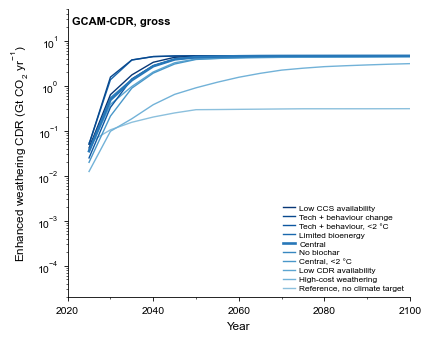

In [13]:
def load_fuhrman():
    path = os.path.join(RAW, "fuhrman2023_gcamcdr_output_data.zip")
    zf = zipfile.ZipFile(fs.open(path))
    wanted = ("queryout_CO2_sequestration_by_tech_global.csv",
              "queryout_CO2_sequestration_by_tech_regionalized.csv")
    for name in sorted(n for n in zf.namelist() if n.endswith(wanted)):
        scenario = name.split("/")[1]
        # The regionalized file repeats the Global aggregate, so drop it there.
        regionalized = name.endswith("regionalized.csv")
        rows = list(csv.reader(io.TextIOWrapper(zf.open(name), "utf-8")))
        # Row 0 is a query title, row 1 the real header.
        years = {int(h): i for i, h in enumerate(rows[1]) if h.strip().isdigit()}
        for row in rows[2:]:
            if len(row) < 6 or row[3] != "rock weathering":
                continue
            if regionalized and row[1] == "Global":
                continue
            for year, i in years.items():
                raw = row[i].strip()
                if not raw:
                    continue
                cdr = float(raw) * MTC_TO_GTCO2
                add("fuhrman2023_gcamcdr", "GCAM-CDR", scenario, row[1],
                    "erw_cdr_GtCO2_per_yr", year, cdr)
                add("fuhrman2023_gcamcdr", "GCAM-CDR", scenario, row[1],
                    "basalt_applied_Gt_per_yr", year, cdr / T_CO2_PER_T_ROCK)


load_and_plot(load_fuhrman, "fuhrman2023_gcamcdr")

### GCAM 6.0 (Fuhrman et al. 2024)

Technology `rock weathering` in sector `CO2 removal`, MtC converted to Gt CO2, `Global` plus 32 regions, 5-year steps, from each run's `queryout_CO2_sequestration_by_tech_regionalized.csv` (here zipped into `raw/fuhrman2024_gcam_output_data.zip`). The paper's two main runs: Global Carbon Cap, and Max Sectoral Effort, which cuts residual emissions further and so needs less CDR.

Left out: Sectoral Strengthening (`cwf-flagship`), which appears to be the same GCAM run as GCAM-CDR's `exe_techBehaviorChange1p5` above (ERW matches to 0.1 Mt CO2/yr), and the SI-only Low Demand, No New Tech run.

**Gross CDR**: GCAM sequestration, as for GCAM-CDR.

Data: [paper 10.1088/1748-9326/ad456d](https://doi.org/10.1088/1748-9326/ad456d); query outputs (`data/gcam-1p5`, `data/cwf-min-viable-cdr`) from the authors' `min-viable-CDR` repository


wrote figures/by_study/fuhrman2024_gcam.pdf


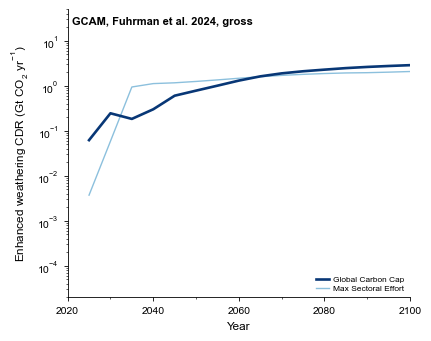

In [14]:
def load_fuhrman2024():
    zf = zipfile.ZipFile(fs.open(os.path.join(RAW, "fuhrman2024_gcam_output_data.zip")))
    for name in sorted(n for n in zf.namelist() if n.endswith(".csv")):
        scenario = name.split("/")[0]
        rows = list(csv.reader(io.TextIOWrapper(zf.open(name), "utf-8")))
        # Row 0 is a query title, row 1 the real header; `Global` is the sum of the regions.
        years = {int(h): i for i, h in enumerate(rows[1]) if h.strip().isdigit()}
        for row in rows[2:]:
            if len(row) < 6 or row[3] != "rock weathering":
                continue
            for year, i in years.items():
                raw = row[i].strip()
                if raw:
                    add("fuhrman2024_gcam", "GCAM 6.0", scenario, row[1],
                        "erw_cdr_GtCO2_per_yr", year, float(raw) * MTC_TO_GTCO2)


load_and_plot(load_fuhrman2024, "fuhrman2024_gcam")


### REMIND-MAgPIE (Strefler et al. 2021)

Variable `Carbon Sequestration|Enhanced Weathering` (Mt CO2/yr, negative = removal), `World` plus 12 regions. Only 6 of the 20 scenarios deploy ERW; the others have it switched off and are left out of the plots.

**Gross CDR** (a `Carbon Sequestration` variable).

Data: [Zenodo 10.5281/zenodo.4313059](https://doi.org/10.5281/zenodo.4313059)

wrote figures/by_study/strefler2021_remind.pdf


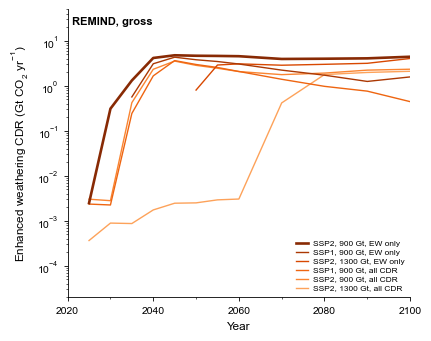

In [15]:
def load_remind():
    path = os.path.join(RAW, "strefler2021_remind.mif")
    with fs.open(path, "r") as f:
        reader = csv.reader(f, delimiter="\t")
        header = next(reader)
        years = [(i + 5, int(y)) for i, y in enumerate(header[5:]) if y.strip()]
        for row in reader:
            if len(row) < 6 or row[3] != "Carbon Sequestration|Enhanced Weathering":
                continue
            for idx, year in years:
                raw = row[idx].strip()
                if not raw:
                    continue
                # The .mif labels runs REMIND or REMIND-MAGPIE; all are the same REMIND-MAgPIE setup
                add("strefler2021_remind", "REMIND-MAgPIE", row[1], row[2],
                    "erw_cdr_GtCO2_per_yr", year, abs(float(raw)) / 1000.0)


load_and_plot(load_remind, "strefler2021_remind")

### GET-ACC2 (Gaucher et al. 2025)

Source Data sheets `Figure 2` (ERW CDR, geochemical + biotic) and `Figure 7` (basalt applied), both ensemble means, decadal 2020–2100. Runs are 4 climate targets × ERW on croplands (CL) or croplands + forests (CL+F).

**Gross CDR**: basalt supply emissions are reported separately. The total includes a biotic part (the ecosystem response, 39–86% of the peak in the CL+F runs), so the geochemical part is plotted on its own as well; it is the closer comparison to the other studies.

Data: [paper 10.1038/s41467-025-58284-6](https://doi.org/10.1038/s41467-025-58284-6), Source Data

wrote figures/by_study/getacc2_nc2025.pdf
wrote figures/by_study/getacc2_nc2025_geochemical.pdf


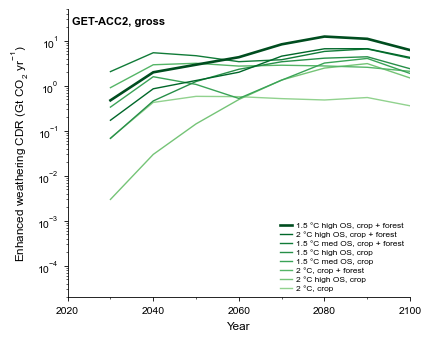

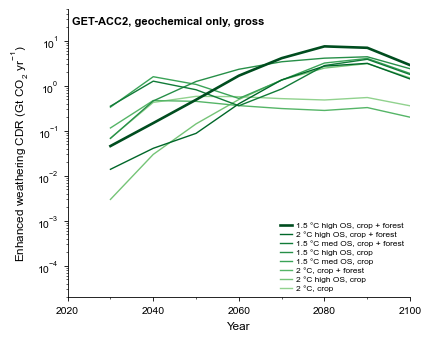

In [16]:
# Minimal .xlsx reader (standard library only), also used by the Kantzas and Madankan loaders.
def _sheet_grid(zf, strings, sheet_path):
    """Return the sheet as a list of {column letter: cell text} dicts."""
    root = ET.fromstring(zf.read(sheet_path))
    grid = []
    for row in root.iter(NS + "row"):
        cells = {}
        for c in row.iter(NS + "c"):
            col = "".join(ch for ch in c.get("r") if ch.isalpha())
            v = c.find(NS + "v")
            if v is None:
                continue
            cells[col] = strings[int(v.text)] if c.get("t") == "s" else v.text
        grid.append(cells)
    return grid


def _num(cells, col):
    raw = cells.get(col, "")
    try:
        return float(raw)
    except (TypeError, ValueError):
        return None


def _sheets(zf):
    """{sheet name: worksheet path inside the .xlsx}."""
    rid = "{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id"
    rels = {r.get("Id"): r.get("Target")
            for r in ET.fromstring(zf.read("xl/_rels/workbook.xml.rels"))}
    out = {}
    for sheet in ET.fromstring(zf.read("xl/workbook.xml")).iter(NS + "sheet"):
        target = rels[sheet.get(rid)]
        out[sheet.get("name")] = target[1:] if target.startswith("/") else "xl/" + target
    return out


def _shared_strings(zf):
    return ["".join(t.text or "" for t in si.iter(NS + "t"))
            for si in ET.fromstring(zf.read("xl/sharedStrings.xml")).iter(NS + "si")]


def load_getacc2():
    path = os.path.join(RAW, "getacc2_nc2025_SourceData.xlsx")
    zf = zipfile.ZipFile(fs.open(path))
    strings = _shared_strings(zf)

    # Figure 2: blocks of 22 rows; row 0 is (climate target, EW setting),
    # row 1 is the column header, rows 2-12 are decadal 2020-2100.
    fig2 = _sheet_grid(zf, strings, "xl/worksheets/sheet1.xml")
    for start in range(0, len(fig2), 22):
        head = fig2[start]
        target, setting = head.get("A"), head.get("B")
        if not target or not setting:
            continue
        scenario = "%s / %s" % (target, setting)
        for cells in fig2[start + 2:start + 13]:
            year = _num(cells, "A")
            if year is None:
                continue
            geochem = _num(cells, "K") or 0.0
            biotic = _num(cells, "L") or 0.0
            add("getacc2_nc2025", "GET-ACC2", scenario, "World",
                "erw_cdr_GtCO2_per_yr", int(year), geochem + biotic)
            add("getacc2_nc2025", "GET-ACC2", scenario + " [geochemical]", "World",
                "erw_cdr_GtCO2_per_yr", int(year), geochem)
            add("getacc2_nc2025", "GET-ACC2", scenario + " [biotic]", "World",
                "erw_cdr_GtCO2_per_yr", int(year), biotic)

    # Figure 7: blocks of 14 rows; croplands in columns A-E, forests in F-J.
    # Column B is the ensemble mean, C the median. Use the means: Figure 2's CDR
    # is the ensemble mean, and means of croplands and forests add to the mean of
    # the total, which medians do not.
    fig7 = _sheet_grid(zf, strings, "xl/worksheets/sheet7.xml")
    for start in range(0, len(fig7), 14):
        head = fig7[start]
        target, setting = head.get("A"), head.get("B")
        if not target or not setting:
            continue
        # Figure 7 abbreviates the targets; use Figure 2's names so the basalt
        # and CDR rows of a run share a scenario name.
        target = (target.replace(" high OS", " with high overshoot")
                  .replace(" medium OS", " with medium overshoot"))
        scenario = "%s / %s" % (target, setting)
        for cells in fig7[start + 3:start + 12]:
            year = _num(cells, "A")
            if year is None:
                continue
            crop = _num(cells, "B") or 0.0     # mean, croplands
            forest = _num(cells, "G") or 0.0   # mean, forests
            add("getacc2_nc2025", "GET-ACC2", scenario, "World",
                "basalt_applied_Gt_per_yr", int(year), crop + forest)


load_and_plot(load_getacc2, "getacc2_nc2025")
print("wrote", plot_study("getacc2_nc2025", getacc2="geochemical"))

### SCORE (Schaber et al. 2024)

Reads a table pre-extracted from the GAMS `.gdx` output (`intermediate/`): the mean over each run's climate-sensitivity paths. ERW is zero before 2050 and then capped by a linear ceiling (2.5 / 3.75 / 5.0 Gt CO2/yr by 2100), so the trajectory is mostly an input.

**Net or gross not stated**: ERW enters the model as a removal potential.

Data: [Zenodo 10.5281/zenodo.11230655](https://doi.org/10.5281/zenodo.11230655)

wrote figures/by_study/schaber2024_score.pdf


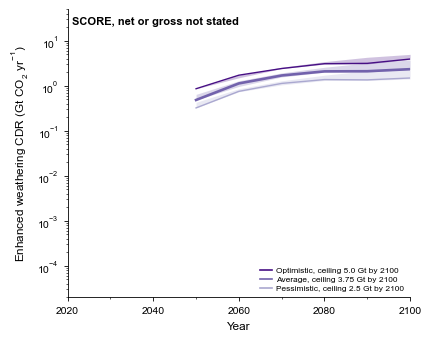

In [17]:
def load_score():
    path = os.path.join(PROC, "schaber2024_score_curve.csv")
    with fs.open(path, "r") as f:
        for row in csv.DictReader(f):
            add("schaber2024_score", "SCORE", row["run"], "World",
                "erw_cdr_GtCO2_per_yr", int(row["year"]),
                float(row["erw_cdr_GtCO2_per_yr_mean"]))


load_and_plot(load_score, "schaber2024_score")

### Tu et al. (2026) diffusion model

A technology-diffusion model, not a cost-optimizing IAM. Global, annual 2026–2100, 5 scenarios.

**Gross CDR**: modelled sequestration; logistics emissions are not subtracted.

Data: [GitHub thutyecology/ERW](https://github.com/thutyecology/ERW); [paper 10.1038/s44458-026-00034-w](https://doi.org/10.1038/s44458-026-00034-w)

wrote figures/by_study/tu2026_diffusion.pdf


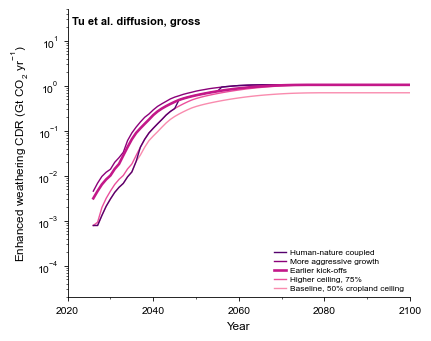

In [18]:
def load_tu():
    path = os.path.join(RAW, "tu2026_global_annual_CDR.csv")
    with fs.open(path, "r") as f:
        for row in csv.DictReader(f):
            year = int(row["Year"])
            for scen in [c for c in row if c != "Year"]:
                add("tu2026_diffusion", "Tu-diffusion", scen, "World",
                    "erw_cdr_GtCO2_per_yr", year, float(row[scen]))


load_and_plot(load_tu, "tu2026_diffusion")

### Beerling et al. (2025), US

Reads a table pre-extracted from the gridded output (`intermediate/`): 5483 US cropland points summed to national totals, 2020–2070. Deployment is prescribed (two ramps); low / mean / high vary only removal efficiency.

**Gross CDR**: CO2 captured; mining, grinding, transport and spreading emissions are separate fluxes in the archive and are not subtracted.

Data: [Zenodo 10.5281/zenodo.14755423](https://doi.org/10.5281/zenodo.14755423)

wrote figures/by_study/beerling2025_usa.pdf


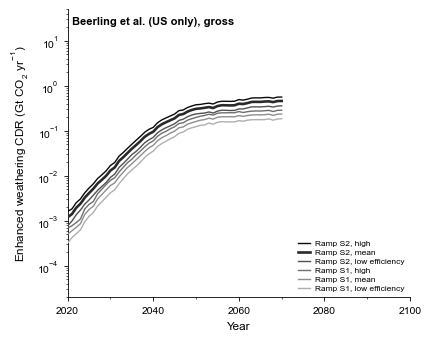

In [19]:
def load_beerling():
    path = os.path.join(PROC, "beerling2025_usa_curve.csv")
    with fs.open(path, "r") as f:
        for row in csv.DictReader(f):
            scenario = "%s (%s)" % (row["scenario"], row["uncertainty"])
            year = int(row["year"])
            add("beerling2025_usa", "Beerling-US", scenario, "USA",
                "basalt_applied_Gt_per_yr", year,
                float(row["basalt_applied_Gt_per_yr"]))
            add("beerling2025_usa", "Beerling-US", scenario, "USA",
                "erw_cdr_GtCO2_per_yr", year,
                float(row["erw_cdr_GtCO2_per_yr"]))


load_and_plot(load_beerling, "beerling2025_usa")

### GCAM-USA (Javadi et al. 2026)

`rock weathering` removal by US state (MtC), summed to a US total for the plots; the state rows are kept for section 5. Two scenarios; runs end in 2050.

**Gross CDR**: the same GCAM sequestration output as GCAM-CDR.

Data: [Zenodo 10.5281/zenodo.18760906](https://doi.org/10.5281/zenodo.18760906), file `Supplementary_Data/CO2 emissions and removal/states_neg_tech.csv` in `CDR_Tradeoffs.zip`

wrote figures/by_study/javadi2026_gcamusa.pdf


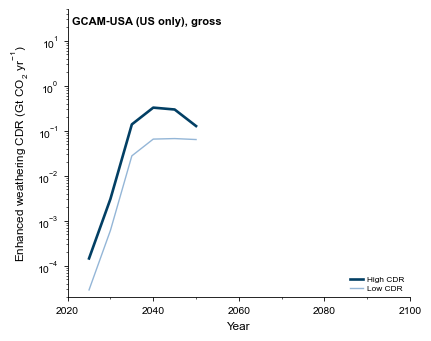

In [20]:
def load_javadi():
    path = os.path.join(RAW, "javadi2026_gcamusa_states_neg_tech.csv")
    totals, states = {}, {}
    with fs.open(path, "r") as f:
        for row in csv.DictReader(f):
            if row["technology"] != "rock weathering":
                continue
            scenario = row["scenario"].split(",")[0]
            acc = totals.setdefault(scenario, {})
            st = states.setdefault((scenario, row["region"]), {})
            for col, raw in row.items():
                if col.isdigit():
                    acc[int(col)] = acc.get(int(col), 0.0) + float(raw)
                    st[int(col)] = st.get(int(col), 0.0) + float(raw)
    # Runs end in 2050; the later columns are zero placeholders.
    for scenario, series in totals.items():
        assert not any(v for y, v in series.items() if y > 2050), scenario
        for year, mtc in sorted(series.items()):
            if year <= 2050:
                add("javadi2026_gcamusa", "GCAM-USA", scenario, "USA",
                    "erw_cdr_GtCO2_per_yr", year, mtc * MTC_TO_GTCO2)
    # State rows too, for the peak-year fluxes in section 5.
    for (scenario, state), series in states.items():
        for year, mtc in sorted(series.items()):
            if year <= 2050:
                add("javadi2026_gcamusa", "GCAM-USA", scenario, state,
                    "erw_cdr_GtCO2_per_yr", year, mtc * MTC_TO_GTCO2)


load_and_plot(load_javadi, "javadi2026_gcamusa")

### Kantzas et al. (2022), UK

Annual net CDR 2020–2070 (Source Data Fig. 1) and rock demand (Fig. 4). Three rock-extraction scenarios × 3 removal efficiencies × 7 grain sizes, plotted as one band per scenario; the line is median efficiency at p80 = 100 µm. Section 5's fluxes use the Fig. 2 grids instead: decade-mean CDR per treated cell.

**Net CDR**: logistics emissions are subtracted (paper, Fig. 1).

Data: [paper 10.1038/s41561-022-00925-2](https://doi.org/10.1038/s41561-022-00925-2), Source Data Figs. 1, 2 and 4

wrote figures/by_study/kantzas2022_uk.pdf


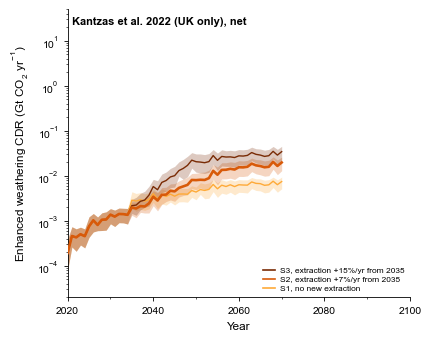

In [21]:
# Dates in these workbooks are Excel serial numbers.
def _excel_year(serial):
    return (datetime.date(1899, 12, 30) + datetime.timedelta(days=int(serial))).year


def load_kantzas2022():
    zf = zipfile.ZipFile(fs.open(os.path.join(RAW, "kantzas2022_uk_SourceData_Fig4.xlsx")))
    grid = _sheet_grid(zf, _shared_strings(zf), "xl/worksheets/sheet1.xml")
    rock = {}  # {"S1": {year: Mt}}
    for cells in grid[1:]:
        date = _num(cells, "A")
        for col, scen in (("F", "S1"), ("G", "S2"), ("H", "S3")):
            value = _num(cells, col)
            if date is not None and value is not None:
                rock.setdefault(scen, {})[_excel_year(date)] = value

    zf = zipfile.ZipFile(fs.open(os.path.join(RAW, "kantzas2022_uk_SourceData_Fig1.xlsx")))
    grid = _sheet_grid(zf, _shared_strings(zf), "xl/worksheets/sheet1.xml")
    header = grid[0]
    for cells in grid[1:]:
        date = _num(cells, "A")
        if date is None:
            continue
        year = _excel_year(date)
        for col, scenario in header.items():
            value = _num(cells, col)
            if col == "A" or value is None:
                continue
            add("kantzas2022_uk", "Kantzas-UK", scenario, "UK",
                "erw_cdr_GtCO2_per_yr", year, value / 1000.0)
            mt = rock[scenario.split("_")[0]].get(year)
            if mt is not None:
                add("kantzas2022_uk", "Kantzas-UK", scenario, "UK",
                    "basalt_applied_Gt_per_yr", year, mt / 1000.0)


load_and_plot(load_kantzas2022, "kantzas2022_uk")

### Madankan et al. (2025), UK

Rock supply (Mt/yr) and CDR (Mt CO2/yr), 2025–2070. S1–S3 are low / medium / high rock supply; `.a/.b/.c` are quarry size caps.

Not a weathering model: it allocates quarry rock to GB cropland, scaling the per-cell CDR of Kantzas et al. (2022) by each quarry's rock (paper, Eq. 1), with Kantzas 2022's rock-supply scenarios as targets. Section 5 divides its CDR by the area treated, rock ÷ the paper's 40 t/ha application rate (Methods).

**Net CDR**: the paper's model subtracts extraction, grinding, transport and spreading emissions.

Data: [paper 10.1038/s43247-025-02656-9](https://doi.org/10.1038/s43247-025-02656-9), Supplementary Data 1

wrote figures/by_study/madankan2025_uk.pdf


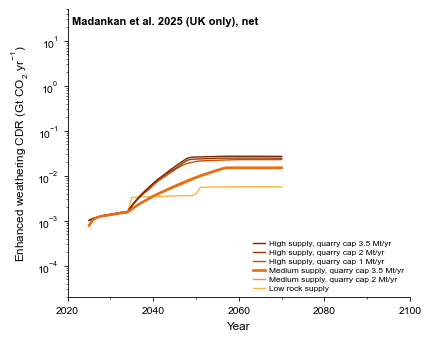

In [22]:
def load_madankan2025():
    zf = zipfile.ZipFile(fs.open(os.path.join(RAW, "kantzas2025_uk_SupplementaryData1.xlsx")))
    strings = _shared_strings(zf)
    for sheet, variable in (("sheet1", "basalt_applied_Gt_per_yr"),
                            ("sheet2", "erw_cdr_GtCO2_per_yr")):
        grid = _sheet_grid(zf, strings, "xl/worksheets/%s.xml" % sheet)
        header = grid[1]
        assert header.get("A") == "Year", header
        for cells in grid[2:]:
            year = _num(cells, "A")
            if year is None:
                continue
            for col, scenario in header.items():
                value = _num(cells, col)
                if col != "A" and value is not None:
                    add("madankan2025_uk", "Madankan-UK-quarry", scenario, "UK",
                        variable, int(year), value / 1000.0)


load_and_plot(load_madankan2025, "madankan2025_uk")

### GCAM 7.4 (Chadsey et al. 2026)

Variable `Carbon Removal|Enhanced Weathering` (Mt CO2/yr), `World` plus 32 regions, 5-year steps. Runs meet countries' NDC and LT-LEDS pledges with limited emissions trade or Article 6 trade, with and without biochar; one has the US backslide to reference emissions. The paper compares three models, but only GCAM output is deposited (IMAGE and MESSAGE are on request). The Article 6 low-CDR run was added to the deposit later as a raw 4 GB GCAM database dump (`sensitivity_lowCDR.zip`) and is not read here.

**Gross CDR**: GCAM sequestration, as for GCAM-CDR.

Data: [Zenodo 10.5281/zenodo.17612900](https://doi.org/10.5281/zenodo.17612900), file `GCAM_NDCs_CDR_IAMC_Format.csv`

wrote figures/by_study/chadsey2026_gcam.pdf


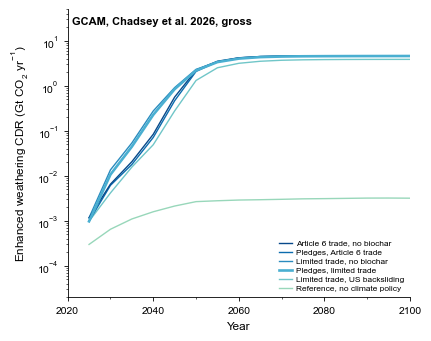

In [23]:
def load_chadsey():
    path = os.path.join(RAW, "chadsey2026_gcam_NDCs_CDR_IAMC_Format.csv")
    with fs.open(path, "r") as f:
        for row in csv.DictReader(f):
            if row["Variable"] != "Carbon Removal|Enhanced Weathering":
                continue
            assert row["Unit"] == "Mt CO2/yr", row["Unit"]
            for col, raw in row.items():
                if col.isdigit() and raw.strip():
                    add("chadsey2026_gcam", row["Model"], row["Scenario"], row["Region"],
                        "erw_cdr_GtCO2_per_yr", int(col), float(raw) / 1000.0)


load_and_plot(load_chadsey, "chadsey2026_gcam")

### REMIND-MAgPIE overshoot (Bauer et al. 2023)

Variable `Emi|CO2|CDR|EW` (Mt CO2/yr, negative = removal), `World` plus 12 regions, 5-year steps to 2060, then 10-year. Both runs meet a 600 Gt CO2 budget under a carbon price that starts in 2025. In the full-overshoot run, net-negative emissions earn the carbon price, and ERW scales up after 2060. In the minimal-overshoot run they earn nothing, and ERW goes in at once, peaking at 4.4 Gt CO2/yr in 2030. The NDC run has no ERW and is left out of the plots.

**Gross CDR** (REMIND's `Emi|CO2|CDR` removal variable).

Data: [Zenodo 10.5281/zenodo.7777223](https://doi.org/10.5281/zenodo.7777223), file `REMIND_MAgPIE_scenarios.csv`

wrote figures/by_study/bauer2023_remind.pdf


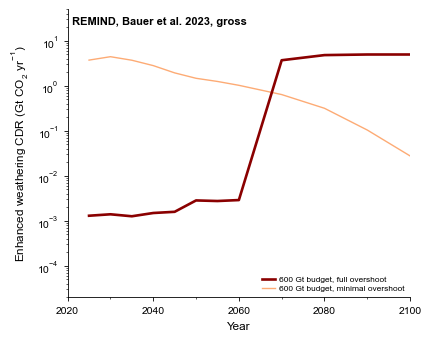

In [24]:
def load_bauer():
    path = os.path.join(RAW, "bauer2023_remind_REMIND_MAgPIE_scenarios.csv")
    with fs.open(path, "r") as f:
        for row in csv.DictReader(f, delimiter=";"):
            if row["Variable"] != "Emi|CO2|CDR|EW":
                continue
            for col, raw in row.items():
                if col and col.isdigit() and raw.strip():
                    add("bauer2023_remind", row["Model"], row["Scenario"], row["Region"],
                        "erw_cdr_GtCO2_per_yr", int(col), abs(float(raw)) / 1000.0)


load_and_plot(load_bauer, "bauer2023_remind")

### REMIND 3.2, separate targets (Merfort et al. 2025)

Variable `Emi|CO2|CDR|EW` (Mt CO2/yr, negative = removal), `World` plus 12 regions, 5-year steps to 2060, then 10- and 20-year steps to 2150. All seven runs reach global net-zero CO2 in 2050, with equal quantity targets for residual emissions and novel CDR (nCDR) of 2–12 Gt CO2/yr. At 7 Gt the emission and removal prices come out equal; the paper uses that run as its benchmark.

Reads a table pre-extracted from the 3.7 GB archive (`intermediate/`): the EW rows of `SepMark3_2_0/plotting/data/2023_July/SepMark_N.mif`. The archive also has runs without the 100 EJ biomass cap (`noBiolimSepMark_N`, Supplementary Fig. 2) and uniform-price counterfactuals (`2050BudgNNN_N`), which are not used here.

**Gross CDR** (REMIND's `Emi|CO2|CDR` removal variable; EW's diesel and electricity use are separate `FE|CDR|EW` variables).

Data: [Zenodo 10.5281/zenodo.15367999](https://doi.org/10.5281/zenodo.15367999), `SepMark_essential.zip`

wrote figures/by_study/merfort2025_remind.pdf


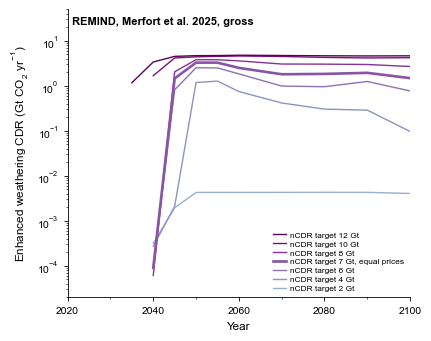

In [25]:
def load_merfort():
    path = os.path.join(PROC, "merfort2025_remind_EW.csv")
    with fs.open(path, "r") as f:
        for row in csv.DictReader(f):
            for col, raw in row.items():
                if col.isdigit() and raw.strip():
                    add("merfort2025_remind", row["Model"], row["file"], row["Region"],
                        "erw_cdr_GtCO2_per_yr", int(col), abs(float(raw)) / 1000.0)


load_and_plot(load_merfort, "merfort2025_remind")

### EPPA (Chiquier et al. 2025), digitized

Did not find a data deposit, so we had to digitize this one. ERW is the `Enhanced Weathering` band of the stacked removals in Fig. 2A (CDR Portfolio, Constrained CDR Portfolio) and Fig. SM6.1 (the constrained portfolio with low, high and very high CDR costs).

Band thickness was measured at each 5-year step and scaled with the 10 Gt gridlines (`digitize_chiquier2025.py`). The scale is about 4.7 px per Gt, so values are good to about ±0.2 Gt. Bands thinner than 2 px (~0.4 Gt) can't be told apart from their neighbours and are left blank, so each run starts at its first resolvable year (2035–2065), not at first deployment.

Check against the text, ERW in 2100: 7.6 Gt digitized vs 7.7 Gt stated (CDR Portfolio); 3.15 vs 3.2 Gt (Constrained); 3.1–3.8 vs 3.1–3.8 Gt (cost sensitivities).

**Gross CDR**: CO2 stored; the electricity for grinding is an input to the energy system.

Data: [paper 10.1088/1748-9326/ada4c0](https://doi.org/10.1088/1748-9326/ada4c0), Fig. 2A and Supplementary Fig. SM6.1

wrote figures/by_study/chiquier2025_eppa.pdf


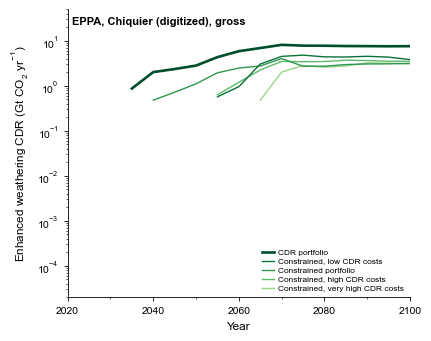

In [26]:
def load_chiquier():
    path = os.path.join(PROC, "chiquier2025_eppa_digitized.csv")
    with fs.open(path, "r") as f:
        for row in csv.DictReader(f):
            if row["erw_cdr_GtCO2_per_yr"]:  # blank: band too thin to digitize
                add("chiquier2025_eppa", "EPPA", row["scenario"], "World",
                    "erw_cdr_GtCO2_per_yr", int(row["year"]),
                    float(row["erw_cdr_GtCO2_per_yr"]))


load_and_plot(load_chiquier, "chiquier2025_eppa")

### C-ROADS and En-ROADS (Holz et al. 2018)

Supplementary Tables 1 (C-ROADS) and 2 (En-ROADS): variable `Carbon Sequestration|Enhanced Weathering` (Mt CO2/yr), `World` only, annual. CDR is prescribed, not optimized: in allCDR every CDR type ramps up to 50% of its maximum literature potential. Only allCDR deploys ERW, from 2031 to 2.5 Gt CO2/yr by 2100. The other runs have none and are left out of the plots. En-ROADS reruns allCDR with an explicit energy system.

**Gross CDR**: supply-chain emissions are not modelled. (The paper's gross vs net is about storage losses, which are zero for ERW.)

Data: [paper 10.1088/1748-9326/aac0c1](https://doi.org/10.1088/1748-9326/aac0c1), Supplementary Tables 1–2. The models and scenario files (Supplementary Data Files 1–2) need Vensim to run.

wrote figures/by_study/holz2018_croads.pdf


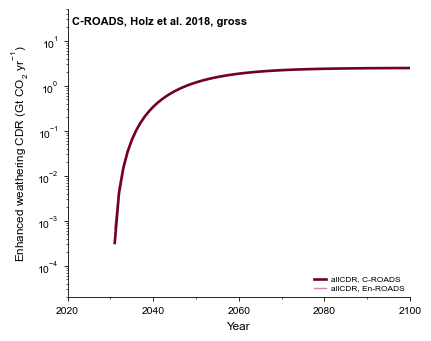

In [27]:
def load_holz():
    for name, model in (("holz2018_croads_SD_Table_1.xlsx", "C-ROADS"),
                        ("holz2018_enroads_SD_Table_2.xlsx", "En-ROADS")):
        zf = zipfile.ZipFile(fs.open(os.path.join(RAW, name)))
        strings = _shared_strings(zf)
        for sheet, sheet_path in _sheets(zf).items():
            grid = _sheet_grid(zf, strings, sheet_path)
            header = grid[0]
            # One sheet per run; skips variable_definitions and comments.
            if header.get("D") != "Variable" or header.get("E") != "Unit":
                continue
            years = {col: int(h) for col, h in header.items() if h.isdigit()}
            for cells in grid[1:]:
                if cells.get("D") != "Carbon Sequestration|Enhanced Weathering":
                    continue
                assert cells.get("E") == "Mt CO2/yr", cells.get("E")
                for col, year in years.items():
                    value = _num(cells, col)
                    if value is not None:
                        add("holz2018_croads", model, "%s %s" % (model, sheet), cells["C"],
                            "erw_cdr_GtCO2_per_yr", year, value / 1000.0)


load_and_plot(load_holz, "holz2018_croads")

### GCAM, Canada (Motlaghzadeh et al. 2025)

`Enhanced weathering` removals in Canada (Mt CO2/yr, negative = removal), 5-year steps, from sheet `Summed_Emissions` of `Features_Final.xlsx`, the table the paper's figure scripts plot. Three targets: Net-Zero 2050, and 1.5 °C equity allocations (PCC-Q, EPC-Q) that add a post-2050 carbon debt of 6.7 and 16.4 Gt CO2. Each target comes with the sensitivity runs of the paper's Figs. 5 and 7, which vary biomass, storage, DAC, EW potential, the land sink, and socio-technological change. One band per target; the line is its baseline run.

Left out: the SI-only carbon-debt variants (EPC-Simple, PCC-Simple, Global 1.5 °C), the `2Q` runs the paper doesn't describe, and the first `STC` runs, superseded by the `_OCT` reruns in Fig. 7. `Outputs_Final.xlsx` in the same archive has the same series, but some run labels are duplicated, so it isn't used.

**Gross CDR**: GCAM sequestration, as for GCAM-CDR.

Data: [Zenodo 10.5281/zenodo.14550600](https://doi.org/10.5281/zenodo.14550600), `Outputs and figure codes/Features_Final.xlsx` in `Inputs and figure codes.zip`

wrote figures/by_study/motlaghzadeh2025_canada.pdf


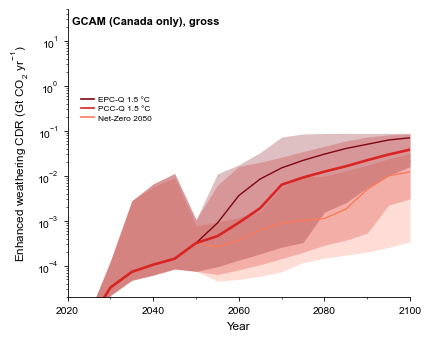

In [28]:
def _motlaghzadeh_run(scenario):
    """Runs in the paper's Figs. 1, 5 and 7."""
    if scenario.endswith(("_STC", "_STC_NoNGDAC")):
        return False  # superseded by the _OCT reruns
    if scenario in ("PCC1.5_NoBioImp_LCostDAC", "EPC1.5_NoBioImp_LCostDAC"):
        return True  # the PCC-Q and EPC-Q low-cost DAC runs, despite the names
    return scenario.split("_")[0] in ("NZ50", "PCC1.5Q", "EPC1.5Q")


def load_motlaghzadeh():
    zf = zipfile.ZipFile(fs.open(os.path.join(RAW, "motlaghzadeh2025_canada_Features_Final.xlsx")))
    grid = _sheet_grid(zf, _shared_strings(zf), _sheets(zf)["Summed_Emissions"])
    header = grid[0]
    assert header.get("A") == "Scenario" and header.get("B") == "plottingsector", header
    years = {col: int(h) for col, h in header.items() if h.isdigit()}
    for cells in grid[1:]:
        if cells.get("B") != "Enhanced weathering" or not _motlaghzadeh_run(cells["A"]):
            continue
        for col, year in years.items():
            value = _num(cells, col)
            if value is not None:
                add("motlaghzadeh2025_canada", "GCAM-CDR", cells["A"], "Canada",
                    "erw_cdr_GtCO2_per_yr", year, abs(value) / 1000.0)


load_and_plot(load_motlaghzadeh, "motlaghzadeh2025_canada")

### GCAM-TJU, Asia (Ampah et al. 2024), read from figures

GCAM 5.4 modified to add biochar, ERW and direct ocean removal, run 2025–2050 for net-zero GHG pathways in Asia, resolved into 11 GCAM regions. Four scenarios: HIGH (all six CDR types, no cap on removal), MODERATE (BECCS and afforestation), LOW (afforestation only) and REFERENCE; only HIGH deploys ERW, reaching 2.2 Gt CO2/yr in 2050.

The Zenodo deposit holds only GCAM-TJU's inputs, so the values come from the article's vector figures, read by `digitize_ampah2024.py` (next to this notebook) into `intermediate/ampah2024_gcamtju_digitized.csv`: Asia's ERW by year from Fig. 3a (HIGH) and ERW by region in 2050 from Fig. 4c. The two figures agree, 2.149 and 2.150 Gt CO2/yr in 2050. The paper says ERW favours China, India and Southeast Asia for their cropland and grassland, but it does not appear that land area constraints are imposed explicitly for rock spreading in the ERW module.

**Gross CDR**: GCAM sequestration, as for GCAM-CDR.

Data: [paper 10.1038/s41467-024-50594-5](https://doi.org/10.1038/s41467-024-50594-5), Figs. 3a and 4c; model inputs at [Zenodo 10.5281/zenodo.11254051](https://doi.org/10.5281/zenodo.11254051)


wrote figures/by_study/ampah2024_gcamtju.pdf


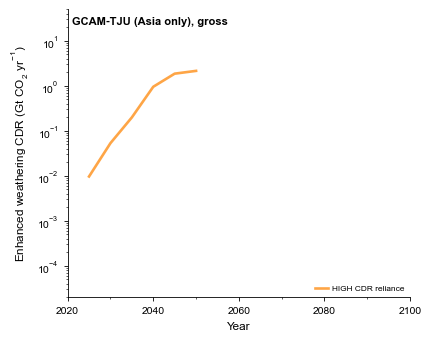

In [29]:
def load_ampah():
    path = os.path.join(PROC, "ampah2024_gcamtju_digitized.csv")
    with fs.open(path, "r") as f:
        for row in csv.DictReader(f):
            add("ampah2024_gcamtju", "GCAM-TJU", row["scenario"], row["region"],
                "erw_cdr_GtCO2_per_yr", int(row["year"]), float(row["erw_cdr_GtCO2_per_yr"]))


load_and_plot(load_ampah, "ampah2024_gcamtju")


### State of CDR, 3rd edition, Chapter 8 (Gidden et al. 2026)

Multi-model comparison with three scenarios: current Targets & Pledges, Highest Ambition, and Delayed Ambition (Targets & Pledges to 2035, then highest ambition). The data portal gives ERW CDR at **2035, 2050 and 2100 only**, so there are no time series. Lines join the reported years, and SoCDR is left out of the growth rates in section 4.

- **Global** (Fig. 8.2a, `Figure 2a: Total CDR by method (harmonized to historical values)`, World only): 7 of the 8 global IAMs model ERW (AIM 3.0, GCAM 8.2, IMAGE 3.4, MESSAGEix-GLOBIOM 2.1, OPEN-PROM 2.0, REMIND-MAgPIE 3.5 and WITCH 6.0). POLES has none, and WITCH has none in Targets & Pledges. The chapter harmonizes CDR to its present-day estimate, which leaves a floor of about 3 kt CO2/yr where a model has no ERW, so values under 0.1 Mt CO2/yr are set to zero. That leaves three runs with no ERW at all (OPEN-PROM Targets & Pledges and Delayed Ambition, REMIND Targets & Pledges). The heavy line is the median of the 7 Highest Ambition runs, the one scenario all 7 models run with ERW.
- **National** (Fig. 8.5, `Figure 5: CDR by method`, 2035 and 2050): of the five national GCAM models, only GCAM-China and GCAM-USA have ERW. Removals are negative in the file and are flipped here. The heavy line is Highest Ambition.

**Gross CDR**: the IAMs' by-method removal, as for the other IAMs.

Data: State of CDR 3rd edition data portal, Chapter 8 download (`SoCDR-Edition-3-Chapter-8.csv`); chapter: Gidden et al. (2026), *Paris-consistent CDR scenarios*.

no ERW: OPEN-PROM 2.0, Delayed Ambition
no ERW: OPEN-PROM 2.0, Targets & Pledges
no ERW: REMIND-MAgPIE 3.5-4.11, Targets & Pledges


wrote figures/by_study/socdr2026_global.pdf
wrote figures/by_study/socdr2026_china.pdf


wrote figures/by_study/socdr2026_usa.pdf


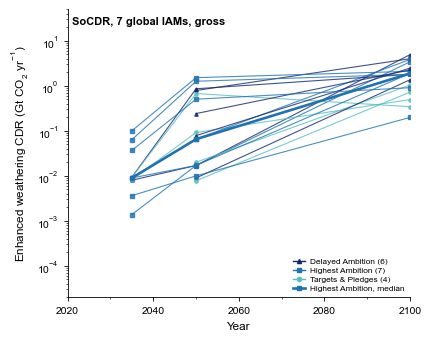

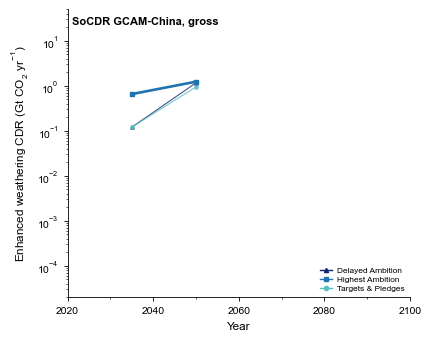

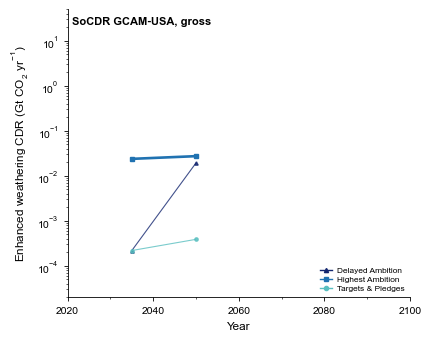

In [30]:
SOCDR_MIN_GT = 1e-4   # 0.1 Mt CO2/yr; below it is the harmonization floor, i.e. no ERW
SOCDR_WHERE = {"World": ("socdr2026_global", "World"), "China": ("socdr2026_china", "China"),
               "United States": ("socdr2026_usa", "USA")}


def load_socdr():
    path = os.path.join(RAW, "SoCDR-Edition-3-Chapter-8.csv")
    runs = {}
    with fs.open(path, "r", encoding="utf-8-sig") as f:
        for row in csv.DictReader(f):
            if row["Type"] != "Enhanced weathering" or not row["Variable"].startswith(("Figure 2a:", "Figure 5: CDR")):
                continue
            assert row["Unit"] == "Gt CO2/yr", row["Unit"]
            source, region = SOCDR_WHERE[row["Region"] if row["Region"] == "World" else row["Country"]]
            key = (source, row["Model"], f"{row['Model']}, {row['Scenario']}", region)
            runs.setdefault(key, {})[int(row["Year"])] = abs(float(row["Value"]))   # Fig. 8.5 is negative
    for (source, model, scenario, region), series in runs.items():
        if max(series.values()) < SOCDR_MIN_GT:
            print("no ERW:", scenario)
            continue
        for year, value in sorted(series.items()):
            add(source, model, scenario, region, "erw_cdr_GtCO2_per_yr", year,
                value if value >= SOCDR_MIN_GT else 0.0)


records[:] = [r for r in records if r[0] not in SOCDR]
load_socdr()
for source in SOCDR:
    print("wrote", plot_study(source))

## 2. Combine into one table

Long format: `source, model, scenario, region, variable, unit, year, value`. Variables are `erw_cdr_GtCO2_per_yr` and `basalt_applied_Gt_per_yr`.

In [31]:
with fs.open(DATA, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(COLUMNS)
    for r in records:
        w.writerow(list(r[:-1]) + [_fmt(r[-1])])

pd.read_csv(DATA).groupby("source").agg(
    regions=("region", "nunique"), runs=("scenario", "nunique"),
    first_year=("year", "min"), last_year=("year", "max"))

,regions,runs,first_year,last_year
source,,,,
ampah2024_gcamtju,12,1,2025,2050
bauer2023_remind,13,3,2005,2100
beerling2025_usa,1,6,2020,2070
chadsey2026_gcam,33,6,2005,2100
chiquier2025_eppa,1,5,2035,2100
fuhrman2023_gcamcdr,33,10,1990,2100
fuhrman2024_gcam,33,2,1990,2100
getacc2_nc2025,1,36,2020,2100
holz2018_croads,1,9,1850,2100


## 3. All studies: CDR

Shared log axis; the last panel shows one representative run per study. SoCDR's are marked at their reported years. `PLOT_GROUPS` and `PLOT_SCOPE` (shared setup) pick the studies, shown in group order; by default IAMs and State of CDR at every scope.

In [32]:
# Studies in the multi-panel figures, chosen by PLOT_GROUPS and PLOT_SCOPE
assert set(PLOT_GROUPS) <= set(STUDY_GROUPS), PLOT_GROUPS
assert PLOT_SCOPE in ("global", "not-global", "all"), PLOT_SCOPE
PLOT_PANELS = tuple(p for p in PANELS
                    if STUDY_GROUP[p[0]] in PLOT_GROUPS and PLOT_SCOPE in ("all", SCOPE[p[0]]))
PLOTTED = {p[0] for p in PLOT_PANELS}
assert PLOT_PANELS, "PLOT_GROUPS and PLOT_SCOPE select no studies"


def mosaic(n, n_cols=3):
    """Layout: three of the n studies per row, then a full-width summary row (the last tag)."""
    tags = "abcdefghijklmnopqrstuvwxyz"[:n + 1]
    rows = [list(tags[:n][i:i + n_cols].ljust(n_cols, ".")) for i in range(0, n, n_cols)]
    return rows + [[tags[-1]] * n_cols], tags


def panel(ax, df, source, region, cmap, central, legend_loc):
    """One study, dispatching on whether its runs are named or grouped."""
    cs = curves(df, source, region)
    if source in SOCDR:
        socdr_panel(ax, cs, cmap, central, legend_loc)
    elif source in GROUPS:
        grouped_panel(ax, cs, GROUPS[source], cmap, central, legend_loc)
    else:
        named_panel(ax, cs, SCENARIOS[source], cmap, central, legend_loc)


def summary_panel(ax, df):
    for source, (name, color, ls) in SUMMARY.items():
        if source not in PLOTTED:
            continue
        _, _, region, _, central, _ = next(p for p in PANELS if p[0] == source)
        y, v = representative(curves(df, source, region), central)
        ax.plot(y, v, color=color, linestyle=ls, linewidth=1.6, marker=SUMMARY_MARKERS.get(source),
                markersize=3.5, label=f"{name}, {CDR_BASIS[source]}")
    if "getacc2_nc2025" in PLOTTED:
        # GET-ACC2 without its biotic part, the closer comparison to the other studies.
        _, _, region, _, central, _ = next(p for p in PANELS if p[0] == "getacc2_nc2025")
        y, v = curves(frame("geochemical"), "getacc2_nc2025", region)[central]
        ax.plot(y, v, color=SUMMARY["getacc2_nc2025"][1], linestyle=(0, (1, 1)), linewidth=1.0,
                label="GET-ACC2 geochemical only, gross")
    # Below the panel: too many studies to fit inside.
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False,
              handlelength=2.6, labelspacing=0.3, columnspacing=1.4)

wrote figures/erw_scenario_panels.pdf


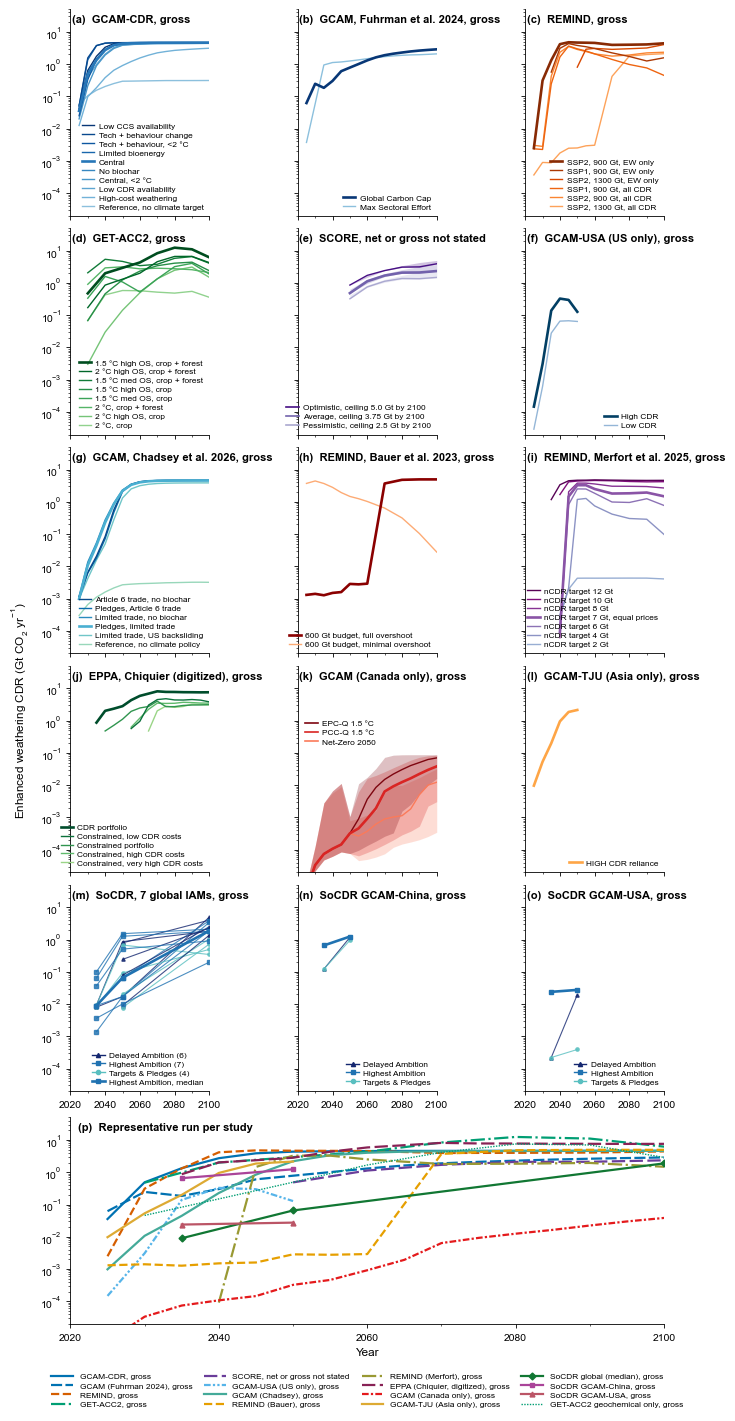

In [33]:
def scenario_panels():
    df = frame()
    layout, tags = mosaic(len(PLOT_PANELS))
    summary = tags[-1]
    fig = plt.figure(figsize=(7.2, 2.35 * len(layout)))
    axd = fig.subplot_mosaic(layout, sharex=True, sharey=True)

    for tag, (source, _, region, cmap, central, loc) in zip(tags, PLOT_PANELS):
        panel(axd[tag], df, source, region, cmap, central, loc)
    summary_panel(axd[summary], df)
    names = [f"{p[1]}, {CDR_BASIS[p[0]]}" for p in PLOT_PANELS] + ["Representative run per study"]

    for i, tag in enumerate(tags):
        ax = axd[tag]
        ax.set_yscale("log")
        ax.set_xlim(YEAR_LO, YEAR_HI)
        ax.set_ylim(Y_BOTTOM, Y_TOP)
        ax.set_xticks(np.arange(2020, 2101, 20))
        ax.set_xticks(np.arange(2020, 2101, 10), minor=True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.tick_params(which="both", direction="out")
        # Label years on the last row of studies too, since the summary spans all columns.
        ax.tick_params(labelbottom=i >= len(PLOT_PANELS) - 3, labelleft=i % 3 == 0 or tag == summary)
        ax.text(0.012, 0.975, f"({tag})  {names[i]}", transform=ax.transAxes,
                fontweight="bold", fontsize=8, va="top", ha="left")
    axd[summary].set_xlabel("Year")
    fig.supylabel("Enhanced weathering CDR (Gt CO$_2$ yr$^{-1}$)", fontsize=8.5)

    path = save_figure(fig, OUTDIR, "erw_scenario_panels")
    print(f"wrote {path}")


scenario_panels()

## 4. Growth rates

Each run's growth rate: least-squares slope of ln(CDR) over a centred 10-year window, as % per year. Grey lines are historical benchmarks (Nemet et al. 2023). Same studies as section 3, less SoCDR, which reports only 2035, 2050 and 2100.

In [34]:
CAGR_Y_BOTTOM, CAGR_Y_TOP = -15, 110

In [35]:
# Window (years) for the growth-rate trend; some studies report by decade.
WINDOW = 10


# Nemet et al. (2023) logistic growth k: median of 148 technologies 0.13, offshore
# wind 0.31 (fastest), as CAGR exp(k) - 1.
BENCHMARKS = (
    ("Historical median (Nemet et al.)", 100 * math.expm1(0.13), (0, (4, 2))),
    ("Fastest historical, offshore wind", 100 * math.expm1(0.31), (0, (1, 1.5))),
)


BENCH_COLOR = "#7f7f7f"

In [36]:
def cagr(years, values):
    """Growth rate (%/yr) per year: least-squares slope of ln(value) over a centred
    WINDOW-year window on an annual grid, reported as exp(slope) - 1."""
    grid = np.arange(YEAR_LO, YEAR_HI + 1, dtype=float)
    with np.errstate(divide="ignore"):
        ln = np.interp(grid, years, np.log(values), left=np.nan, right=np.nan)
    offsets = np.arange(WINDOW + 1) - WINDOW / 2
    weights = offsets / np.sum(offsets ** 2)
    slope = np.lib.stride_tricks.sliding_window_view(ln, WINDOW + 1) @ weights
    half = WINDOW // 2
    return grid[half:-half], 100 * np.expm1(slope)


def reference_lines(ax):
    ax.axhline(0, color="black", linewidth=0.5, zorder=1)
    for label, value, ls in BENCHMARKS:
        ax.axhline(value, color=BENCH_COLOR, linewidth=0.9, linestyle=ls,
                   label=label, zorder=1)

In [37]:
def summary_panel_cagr(ax, df):
    for source, (name, color, ls) in SUMMARY.items():
        if source in SOCDR or source not in PLOTTED:
            continue
        _, _, region, _, central, _ = next(p for p in PANELS if p[0] == source)
        ax.plot(*cagr(*curves(df, source, region)[central]), color=color,
                linestyle=ls, linewidth=1.6, label=f"{name}, {CDR_BASIS[source]}")
    if "getacc2_nc2025" in PLOTTED:
        # GET-ACC2 without its biotic part, the closer comparison to the other studies.
        _, _, region, _, central, _ = next(p for p in PANELS if p[0] == "getacc2_nc2025")
        y, v = cagr(*curves(frame("geochemical"), "getacc2_nc2025", region)[central])
        ax.plot(y, v, color=SUMMARY["getacc2_nc2025"][1], linestyle=(0, (1, 1)), linewidth=1.0,
                label="GET-ACC2 geochemical only, gross")
    reference_lines(ax)
    # Below the panel: too many studies to fit inside.
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False,
              handlelength=2.6, labelspacing=0.3, columnspacing=1.4)

wrote figures/erw_cagr_panels.pdf


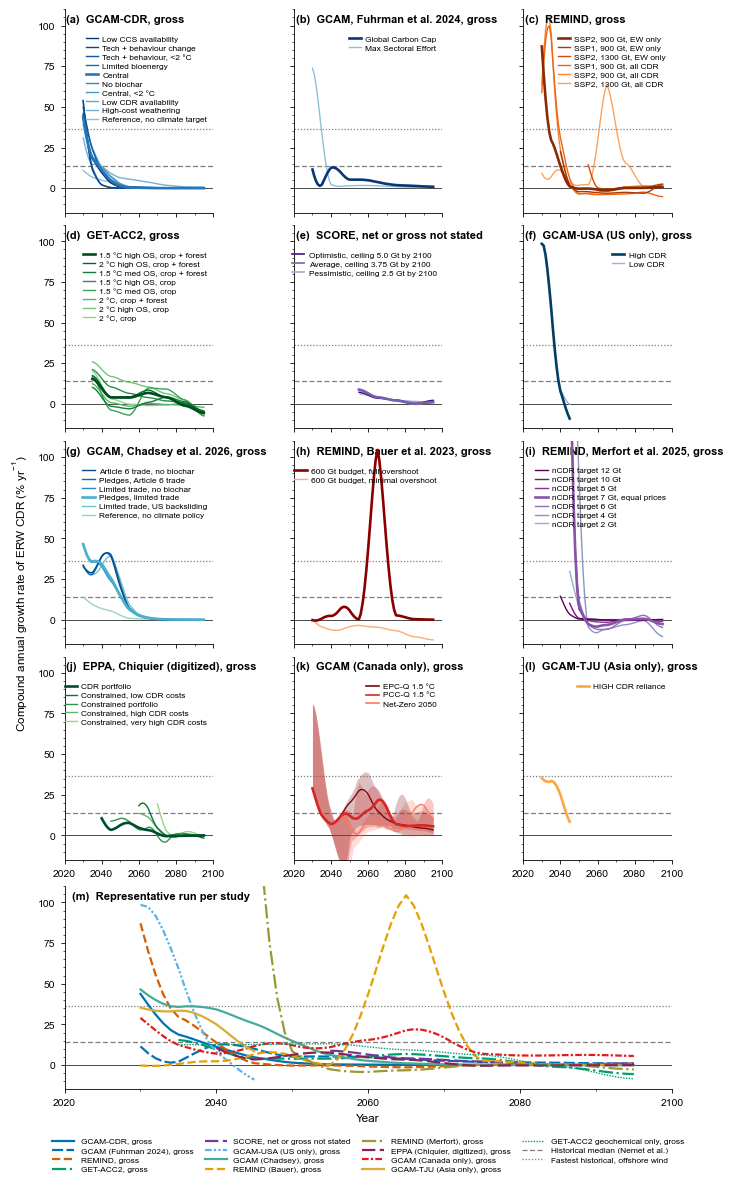

In [38]:
RATE_PANELS = tuple(p for p in PLOT_PANELS if p[0] not in SOCDR)


def cagr_panels():
    df = frame()
    layout, tags = mosaic(len(RATE_PANELS))
    summary = tags[-1]
    fig = plt.figure(figsize=(7.2, 2.35 * len(layout)))
    axd = fig.subplot_mosaic(layout, sharex=True, sharey=True)

    for tag, (source, _, region, cmap, central, _) in zip(tags, RATE_PANELS):
        cs = curves(df, source, region)
        rates = {s: cagr(y, v) for s, (y, v) in cs.items()}
        # Colour by deployment peak so each run matches the previous figure.
        if source in GROUPS:
            grouped_panel(axd[tag], rates, GROUPS[source], cmap, central,
                          "upper right", peaks=peak_levels(cs))
        else:
            named_panel(axd[tag], rates, SCENARIOS[source], cmap, central,
                        "upper right", peaks=peak_levels(cs))
        # Keep the legend clear of the panel label.
        axd[tag].get_legend().set_bbox_to_anchor((0, 0, 1, 0.9),
                                                 transform=axd[tag].transAxes)
        reference_lines(axd[tag])
    summary_panel_cagr(axd[summary], df)
    names = [f"{p[1]}, {CDR_BASIS[p[0]]}" for p in RATE_PANELS] + ["Representative run per study"]

    for i, tag in enumerate(tags):
        ax = axd[tag]
        ax.set_xlim(YEAR_LO, YEAR_HI)
        ax.set_ylim(CAGR_Y_BOTTOM, CAGR_Y_TOP)
        ax.set_xticks(np.arange(2020, 2101, 20))
        ax.set_xticks(np.arange(2020, 2101, 10), minor=True)
        ax.set_yticks(np.arange(0, CAGR_Y_TOP + 1, 25))
        ax.set_yticks(np.arange(-10, CAGR_Y_TOP + 1, 5), minor=True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.tick_params(which="both", direction="out")
        ax.tick_params(labelbottom=i >= len(RATE_PANELS) - 3, labelleft=i % 3 == 0 or tag == summary)
        ax.text(0.012, 0.975, f"({tag})  {names[i]}", transform=ax.transAxes,
                fontweight="bold", fontsize=8, va="top", ha="left")
    axd[summary].set_xlabel("Year")
    fig.supylabel("Compound annual growth rate of ERW CDR (% yr$^{-1}$)",
                  fontsize=8.5)

    path = save_figure(fig, OUTDIR, "erw_cagr_panels")
    print(f"wrote {path}")


if RATE_PANELS:
    cagr_panels()
else:
    print("no studies with growth rates in PLOT_GROUPS / PLOT_SCOPE")


## 5. Peak-year CDR fluxes: the highest-ERW run per reference

Here, we calculate or compile two CDR flux metrics for each reference. We first find the run within that reference that simulates the most ERW CDR in its peak year (the year its total ERW CDR is highest). Then, in that year, we calculate:

- **Highest-region flux**: the largest CDR ÷ area of any one region (GCAM or REMIND region, US state, grid cell, or point).
- **CDR-weighted flux**: Σ(CDR × flux) / ΣCDR across regions, the flux at which the average tonne is removed that year.

We use the reference's own ERW-treated area when available. That includes GET-ACC2's 7.9 Mkm² of warm, wet cropland, each Beerling point's treated area, Kantzas 2022's treated grid cells, and Madankan 2025's rock applied ÷ its 40 t/ha application rate. REMIND models (Strefler, Bauer, Merfort and SoCDR's REMIND-MAgPIE) use REMIND's ERW cropland by region from Strefler et al. (2021) SI Table S4, taken as the maximum ground stone on cropland over the 15 kg/m² limit. Otherwise, area is taken as a share of each region's 2015 cropland, using the Mehrabi et al. (2025) dataset. In those cases, numbers assuming 100 percent, 50 percent, and 25 percent cropland area used for ERW are computed. The 50 percent case comes from Levy et al. 2024, which points out that only half of global croplands are likely suitable for ERW. Since that's a global assumption, the reported data do not apply the 50 percent limit for models that report only one country as a single region --- in those cases, 100 percent of regional cropland is used.

Inputs beyond section 1:
- `intermediate/cropland_area_mehrabi.csv`: cropland by region.
- GCAM-USA's state rows (kept by its loader).
- Kantzas 2022's Fig. 2 grids (`raw/kantzas2022_uk_SourceData_Fig2.zip`, Source Data Fig. 2): decade-mean net CDR in t CO2/ha/yr on 2.5′ cells for S1–S3, the mean of p80 = 10 and 100 µm and three basalts. Each decade is dated at its midpoint, so S3 peaks in "2065", the 2060–2070 mean. The national ensemble's highest run (S3, high efficiency, 10 µm) peaks at 45 Mt CO2/yr in 2070, against 33 Mt here, but has no spatial split.
- Madankan 2025's rock supply (Supplementary Data 1, loaded in section 1). It reports national totals only, so its two fluxes are equal.
- Beerling's per-point CDR for its highest run, S2 high (`intermediate/beerling2025_usa_points_S2high.csv`, extracted from `compiled_run_CO2_a_b_v6_varz.pkl` in [Zenodo 10.5281/zenodo.14755423](https://doi.org/10.5281/zenodo.14755423) by `extract_beerling_points.py`).

GET-ACC2 uses its cropland-only runs (`EW on CL`), since its stated area is cropland. SoCDR's global IAMs use world cropland and its national models their GCAM region's cropland; with only 2035, 2050 and 2100 reported, a SoCDR peak year is one of those. Each SoCDR IAM is its own reference, named `SoCDR-<model> 2026` to mark it as a report's scenario set rather than a peer-reviewed paper. GCAM-CDR's `exe_ref1p5` and Chadsey's `Reference` (no climate target) are left out. GCAM-TJU's regional split comes from Fig. 4c, so it exists only for 2050, its last year and its peak.

Each reference carries its group from `STUDY_GROUPS`: `iams`, `socdr` (State of CDR), or `other` (Tu, Holz, Beerling, Kantzas 2022 and Madankan 2025, where deployment is assumed rather than chosen by an economic model); and its scope, `global` or `not-global`. The table lists every reference, in group order, whatever `PLOT_GROUPS` and `PLOT_SCOPE` say. The table is written to `erw_peak_flux_table.md` on S3. Two cells at the end print versions for manuscript supplements as Quarto tables: for iam-rtm-compare, the studies in `PLOT_GROUPS` and `PLOT_SCOPE`, with one row per model in each study or one per study (`SUPP_RULE`); for beerling-2025-analysis, the references in its peak-flux figure (`plot-cdr.ipynb`), one row each.

In [39]:
CROP_SHARE = 0.5                    # 0.25, 0.5 or 1.0: cropland share for references without a stated area
CROP_SHARES = (1.0, 0.5, 0.25)
PEAK_TABLE = os.path.join(S3, "erw_peak_flux_table.md")

cropland = pd.read_csv(os.path.join(PROC, "cropland_area_mehrabi.csv"))
CROP = {layer: g.set_index("region")["cropland_ha"] for layer, g in cropland.groupby("layer")}

# Cropland layer whose region names match each reference's regions
LAYER = {"fuhrman2023_gcamcdr": "gcam_region", "chadsey2026_gcam": "gcam_region",
         "motlaghzadeh2025_canada": "gcam_region", "strefler2021_remind": "remind_region",
         "bauer2023_remind": "remind_region", "merfort2025_remind": "remind_region",
         "javadi2026_gcamusa": "us_state",
         "schaber2024_score": "world", "tu2026_diffusion": "world", "chiquier2025_eppa": "world",
         "holz2018_croads": "world", "socdr2026_global": "world", "socdr2026_china": "gcam_region",
         "socdr2026_usa": "gcam_region", "fuhrman2024_gcam": "gcam_region",
         "ampah2024_gcamtju": "gcam_region"}
LAYER_NAME = {"gcam_region": "GCAM regions", "remind_region": "REMIND regions", "us_state": "US states"}
# Models that report one country as a single region: all of its cropland (the share is a global assumption)
FULL_CROPLAND = ("socdr2026_china", "socdr2026_usa", "motlaghzadeh2025_canada")
APP_RATE_T_HA = 40.0                                  # Madankan 2025 (Methods): treated area = rock ÷ rate
STATED_AREA_HA = {"getacc2_nc2025": 7.9e8}            # "7.9 Mkm2, i.e., a third of global croplands"
# REMIND's ERW cropland: maximum ground stone on cropland (Gt, warm + temperate) over its 15 kg/m2 limit, from
# Strefler et al. (2021) SI Table S4. The table's area column disagrees for MEA and SSA (warm).
REMIND_STONE_GT = {"CAZ": 0.03 + 2.06, "CHA": 5.96 + 9.74, "EUR": 0.06 + 10.35, "IND": 17.85 + 0.17,
                   "JPN": 0.05 + 1.19, "LAM": 22.16 + 2.64, "MEA": 0.59 + 0.27, "NEU": 0.11 + 0.87,
                   "OAS": 24.83 + 0.48, "REF": 0.00 + 10.98, "SSA": 4.92 + 0.56, "USA": 0.38 + 2.31}
REMIND_AREA_HA = {r: gt * 1e12 / 15 / 1e4 for r, gt in REMIND_STONE_GT.items()}
REMIND_AREA_HA["World"] = sum(REMIND_AREA_HA.values())
EXCLUDE = {"fuhrman2023_gcamcdr": ["exe_ref1p5"], "chadsey2026_gcam": ["Reference"]}   # no climate target
BEERLING_POINTS_RUN = "S2 (high)"                     # the run in beerling2025_usa_points_S2high.csv

REFERENCE = {
    "fuhrman2023_gcamcdr": "Fuhrman et al. (2023)", "strefler2021_remind": "Strefler et al. (2021)",
    "getacc2_nc2025": "Gaucher et al. (2025)", "schaber2024_score": "Schaber et al. (2024)",
    "tu2026_diffusion": "Tu et al. (2026)", "beerling2025_usa": "Beerling et al. (2025)",
    "javadi2026_gcamusa": "Javadi et al. (2026)", "kantzas2022_uk": "Kantzas et al. (2022)",
    "madankan2025_uk": "Madankan et al. (2025)", "chadsey2026_gcam": "Chadsey et al. (2026)",
    "bauer2023_remind": "Bauer et al. (2023)", "merfort2025_remind": "Merfort et al. (2025)",
    "chiquier2025_eppa": "Chiquier et al. (2025)", "holz2018_croads": "Holz et al. (2018)",
    "motlaghzadeh2025_canada": "Motlaghzadeh et al. (2025)",
    "fuhrman2024_gcam": "Fuhrman et al. (2024)", "ampah2024_gcamtju": "Ampah et al. (2024)",
}
# Each SoCDR IAM is its own reference
SOCDR_NAME = {"AIM 3.0": "AIM", "GCAM 8.2": "GCAM", "IMAGE 3.4": "IMAGE", "MESSAGEix-GLOBIOM 2.1-R12": "MESSAGEix-GLOBIOM",
              "OPEN-PROM 2.0": "OPEN-PROM", "REMIND-MAgPIE 3.5-4.11": "REMIND-MAgPIE", "WITCH 6.0": "WITCH",
              "GCAM China CDR v7": "GCAM-China", "GCAM-USA 7.1 SoCDR": "GCAM-USA"}
REFERENCE |= {f"socdr2026:{m}": f"SoCDR-{n} 2026" for m, n in SOCDR_NAME.items()}

In [40]:
def load_kantzas2022_grid():
    """Fig. 2: decade-mean net CDR (t CO2/ha/yr) per 2.5' cell for S1-S3, as t CO2/yr per treated cell.

    A cell with CDR is treated in full. Each decade is dated at its midpoint.
    """
    zf = zipfile.ZipFile(fs.open(os.path.join(RAW, "kantzas2022_uk_SourceData_Fig2.zip")))
    parts = []
    for name in zf.namelist():
        m = re.fullmatch(r"ERW_CDR_DATA/cdr_sc(\d)_(\d{4})_(\d{4})\.txt", name)
        if m is None:
            continue
        lines = zf.read(name).decode().splitlines()
        hdr = {k.lower(): float(v) for k, v in (l.split() for l in lines[:6])}   # ESRI ASCII grid header
        flux = np.array([l.split() for l in lines[6:]], float)
        nrows, ncols, cs = int(hdr["nrows"]), int(hdr["ncols"]), hdr["cellsize"]
        assert flux.shape == (nrows, ncols), name
        edges = hdr["yllcorner"] + cs * (nrows - np.arange(nrows + 1))            # row edges, north to south
        row_ha = 6371.0**2 * np.deg2rad(cs) * -np.diff(np.sin(np.deg2rad(edges))) * 100   # km2 -> ha
        lon = hdr["xllcorner"] + cs * (np.arange(ncols) + 0.5)
        i, j = np.nonzero(flux > 0)                                                # NODATA is -9999
        lat = edges[i] - cs / 2
        parts.append(pd.DataFrame({
            "scenario": f"S{m[1]}", "model": "Kantzas-UK", "year": (int(m[2]) + int(m[3])) // 2,
            "region": [f"cell {a:.2f}°N {abs(b):.2f}°{'W' if b < 0 else 'E'}" for a, b in zip(lat, lon[j])],
            "cdr_t": flux[i, j] * row_ha[i], "area_ha": row_ha[i]}))
    return pd.concat(parts, ignore_index=True)


def load_beerling_points():
    """Per-point CDR (t CO2/yr) for Beerling's highest run, with each point's treated area."""
    df = pd.read_csv(os.path.join(PROC, "beerling2025_usa_points_S2high.csv"))
    meta = ["point", "state", "crop", "area_ha"]
    df = df.melt(meta, var_name="year", value_name="cdr_t")
    df = df[df["cdr_t"] > 0]
    return df.assign(scenario=BEERLING_POINTS_RUN, model="Beerling-US", year=df["year"].astype(int),
                     region=df["crop"] + ", " + df["state"] + " (point " + df["point"].astype(str) + ")")

In [41]:
def regional_cdr():
    """ERW CDR (t CO2/yr) by source, scenario, region and year, with the area each flux divides by."""
    df = frame()                                       # ERW runs; GET-ACC2 as total CDR
    df = df[(df["year"] >= YEAR_LO) & (df["year"] <= YEAR_HI)]
    keep = ["source", "scenario", "model", "region", "year", "cdr_t", "area_ha", "basis"]
    parts = []
    for source, g in df.groupby("source", sort=False):
        g = g[~g["scenario"].isin(EXCLUDE.get(source, []))].assign(cdr_t=lambda d: d["value"] * 1e9)
        if source == "getacc2_nc2025":
            g = g[g["scenario"].str.endswith(" / EW on CL")].assign(area_ha=STATED_AREA_HA[source],
                                                                    basis="stated")
        elif source == "beerling2025_usa":
            # Per point below; check that the extracted run is the one with the most CDR
            tot = g.groupby(["scenario", "year"])["cdr_t"].sum().groupby("scenario").max()
            assert tot.idxmax() == BEERLING_POINTS_RUN, tot.idxmax()
            pts = load_beerling_points()
            peak = pts.groupby("year")["cdr_t"].sum()
            assert abs(peak.max() / tot.max() - 1) < 1e-3, (peak.max(), tot.max())
            parts.append(pts.assign(source=source, basis="treated")[keep])
            continue
        elif source == "kantzas2022_uk":
            grid = load_kantzas2022_grid().assign(basis="grid")       # treated cells in place of the national runs
            # Once the treated area stops growing, the cells sum to the national runs they average
            for scen, sg in grid[grid["year"] == 2065].groupby("scenario"):
                nat = g[g["scenario"].isin([f"{scen}_Med_p8010", f"{scen}_Med_p80100"]) & g["year"].between(2060, 2069)]
                assert abs(sg["cdr_t"].sum() / (nat["cdr_t"].sum() / 20) - 1) < 0.03, scen
            g = grid
        elif source == "madankan2025_uk":
            rock = pd.DataFrame(records, columns=COLUMNS)
            rock = rock[(rock["source"] == source) & (rock["variable"] == "basalt_applied_Gt_per_yr")]
            g = g.merge(rock[["scenario", "year", "value"]].rename(columns={"value": "rock_gt"}),
                        on=["scenario", "year"], validate="1:1")
            g = g.assign(area_ha=g["rock_gt"] * 1e9 / APP_RATE_T_HA, basis="rate")
        else:
            layer = CROP[LAYER[source]]
            inside = g["region"].isin(layer.index)
            dropped = set(g.loc[~inside & (g["cdr_t"] > 0), "region"])
            assert dropped <= {"World", "Global", "USA", "Asia"}, (source, dropped)   # aggregates only
            g = g[inside].assign(area_ha=lambda d: d["region"].map(layer),
                                 basis="cropland_full" if source in FULL_CROPLAND else "cropland")
            remind = g["model"].str.upper().str.startswith("REMIND")   # REMIND's own ERW cropland
            g.loc[remind, "area_ha"] = g.loc[remind, "region"].map(REMIND_AREA_HA)
            g.loc[remind, "basis"] = "remind"
            assert g["area_ha"].notna().all(), source
        parts.append(g.assign(source=source)[keep])
    return pd.concat(parts, ignore_index=True)


def peak_year_fluxes(df):
    """Per source x scenario: peak year of total CDR, then the highest and CDR-weighted fluxes that year."""
    keys = ["source", "scenario"]
    tot = df.groupby(keys + ["year"], as_index=False)["cdr_t"].sum()
    peak = tot.loc[tot.groupby(keys)["cdr_t"].idxmax()].rename(columns={"cdr_t": "total_cdr_t"})
    yr = df.merge(peak[keys + ["year"]], on=keys + ["year"])
    yr = yr[yr["cdr_t"] > 0].assign(flux=lambda d: d["cdr_t"] / d["area_ha"])
    top = yr.loc[yr.groupby(keys)["flux"].idxmax(), keys + ["region", "flux"]]
    w = yr.assign(cf=yr["cdr_t"] * yr["flux"]).groupby(keys)[["cf", "cdr_t"]].sum()
    out = (peak.merge(top.rename(columns={"region": "max_region", "flux": "max_flux"}), on=keys)
               .merge((w["cf"] / w["cdr_t"]).rename("cdrw_flux").reset_index(), on=keys)
               .merge(yr.groupby(keys).agg(regions_with_erw=("region", "nunique"), model=("model", "first"),
                                           basis=("basis", "first"), peak_area_ha=("area_ha", "sum")).reset_index(),
                      on=keys)
               .merge(df.groupby(keys)["year"].max().rename("last_year").reset_index(), on=keys)
               .rename(columns={"year": "peak_year"}))
    out["peak_at_end"] = out["peak_year"] == out["last_year"]
    return out


regional = regional_cdr()
peaks_all = peak_year_fluxes(regional)
# Kantzas 2022's grids are decade means, dated at the midpoint
grid = peaks_all["basis"] == "grid"
peaks_all.loc[grid, "scenario"] += peaks_all.loc[grid, "peak_year"].map(lambda y: f", {y - 5}–{y + 5} mean")
# Highest-ERW run per reference (each SoCDR IAM is one): the most total CDR in its peak year
peaks_all["reference"] = peaks_all["source"].where(~peaks_all["source"].isin(SOCDR), "socdr2026:" + peaks_all["model"])
top_runs = peaks_all.loc[peaks_all.groupby("reference")["total_cdr_t"].idxmax()].set_index("reference")
top_runs = pd.concat([top_runs[top_runs["source"] == p[0]] for p in PANELS])     # panel order

# Fluxes for every cropland share (stated and treated areas are the same in each)
div = {s: np.where(top_runs["basis"] == "cropland", s, 1.0) for s in CROP_SHARES}
pd.DataFrame({f"{name}, {s:.0%}": top_runs[col] / div[s]
              for col, name in (("max_flux", "highest region"), ("cdrw_flux", "CDR-weighted"))
              for s in CROP_SHARES}).rename(index=REFERENCE).round(2)

,"highest region, 100%","highest region, 50%","highest region, 25%","CDR-weighted, 100%","CDR-weighted, 50%","CDR-weighted, 25%"
reference,,,,,,
Fuhrman et al. (2023),8.51,17.02,34.03,4.80,9.61,19.22
Fuhrman et al. (2024),6.96,13.93,27.86,4.00,8.00,16.00
Strefler et al. (2021),8.24,8.24,8.24,7.10,7.10,7.10
Gaucher et al. (2025),5.59,5.59,5.59,5.59,5.59,5.59
Schaber et al. (2024),3.37,6.73,13.46,3.37,6.73,13.46
Javadi et al. (2026),8.48,16.96,33.92,3.21,6.41,12.83
Chadsey et al. (2026),8.48,16.96,33.92,4.80,9.60,19.19
Bauer et al. (2023),8.24,8.24,8.24,7.12,7.12,7.12
Merfort et al. (2025),8.24,8.24,8.24,7.12,7.12,7.12


In [42]:
def area_basis(r, s):
    if r["basis"] == "stated":
        return f"stated area, {STATED_AREA_HA[r["source"]] / 1e8:.1f} Mkm²"
    if r["basis"] == "treated":
        return f"treated area, {r['regions_with_erw']:,} points"
    if r["basis"] == "grid":
        return f"treated area, {r['regions_with_erw']:,} grid cells, {r['peak_area_ha'] / 1e6:.2f} Mha"
    if r["basis"] == "rate":
        return f"treated area, rock ÷ {APP_RATE_T_HA:.0f} t/ha, {r['peak_area_ha'] / 1e6:.2f} Mha"
    if r["basis"] == "remind":
        if r["max_region"] == "World":
            return f"REMIND ERW cropland, {REMIND_AREA_HA['World'] / 1e8:.1f} Mkm²"
        return f"REMIND ERW cropland, {r['regions_with_erw']} REMIND regions"
    s = 1.0 if r["basis"] == "cropland_full" else s
    layer = LAYER[r["source"]]
    if layer == "world":
        return f"{s:.0%} of world cropland"
    if r["regions_with_erw"] == 1:
        return f"{s:.0%} of {r['max_region']} cropland"
    return f"{s:.0%} of cropland, {r['regions_with_erw']} {LAYER_NAME[layer]}"


def peak_flux_table(t, s=CROP_SHARE):
    div = np.where(t["basis"] == "cropland", s, 1.0)
    return pd.DataFrame({
        "Group": t["source"].map(STUDY_GROUP),
        "Scope": t["source"].map(SCOPE),
        "Reference": t.index.map(REFERENCE),
        "Model": t["model"],
        "Scenario": t["scenario"],
        "Peak year": t["peak_year"],
        "Total ERW CDR (Gt CO2/yr)": (t["total_cdr_t"] / 1e9).map(lambda x: f"{x:.3g}"),
        "Area basis": [area_basis(r, s) for _, r in t.iterrows()],
        "Highest region": t["max_region"],
        "Highest-region flux (t CO2/ha/yr)": (t["max_flux"] / div).map(lambda x: f"{x:.2f}"),
        "CDR-weighted flux (t CO2/ha/yr)": (t["cdrw_flux"] / div).map(lambda x: f"{x:.2f}"),
        "Still rising at end of run": t["peak_at_end"].map({True: "yes", False: "no"}),
    }).reset_index(drop=True)


def to_markdown(df, right=(), widths=None):
    """Pipe table; columns in `right` are right-aligned. `widths`: dashes per column, which pandoc reads as
    relative column widths."""
    def row(vals):
        return "| " + " | ".join(str(v).replace("|", "\\|") for v in vals) + " |"
    widths = widths or [3] * len(df.columns)
    rule = "|" + "|".join("-" * w + (":" if c in right else "") for c, w in zip(df.columns, widths)) + "|"
    return "\n".join([row(df.columns), rule] + [row(r) for r in df.itertuples(index=False)])


table = peak_flux_table(top_runs)
numeric = ("Peak year", "Total ERW CDR (Gt CO2/yr)", "Highest-region flux (t CO2/ha/yr)",
           "CDR-weighted flux (t CO2/ha/yr)")
md_text = (f"# ERW CDR fluxes in the peak year: highest-ERW run per reference\n\n"
           f"Area: {CROP_SHARE:.0%} of each region's cropland (Mehrabi et al. 2025) unless the reference states "
           f"its treated area; models that report one country as a single region use all of its cropland; "
           f"REMIND models use REMIND's ERW cropland (Strefler et al. 2021, SI Table S4). "
           f"Kantzas 2022 uses its treated grid cells (Source Data Fig. 2), whose decade means are dated at the "
           f"decade's midpoint; Madankan 2025 uses rock applied ÷ its {APP_RATE_T_HA:.0f} t/ha application rate. "
           f"Peak year: the year of highest total ERW CDR in the run. "
           f"Group: `iams`, `socdr` (State of CDR) or `other` (deployment assumed, not chosen by an economic model). "
           f"Scope: `global` or `not-global`. "
           f"From `iam-rtm-compare/process/synthesis/erw_iam_scenarios.ipynb`, section 5.\n\n" + to_markdown(table, right=numeric) + "\n")
with fs.open(PEAK_TABLE, "w") as f:
    f.write(md_text)
print("wrote", PEAK_TABLE)
display(Markdown(md_text))

wrote s3://carbonplan-carbon-removal/ew-workflows-data/gcam/_iam-synthesis/erw_peak_flux_table.md


# ERW CDR fluxes in the peak year: highest-ERW run per reference

Area: 50% of each region's cropland (Mehrabi et al. 2025) unless the reference states its treated area; models that report one country as a single region use all of its cropland; REMIND models use REMIND's ERW cropland (Strefler et al. 2021, SI Table S4). Kantzas 2022 uses its treated grid cells (Source Data Fig. 2), whose decade means are dated at the decade's midpoint; Madankan 2025 uses rock applied ÷ its 40 t/ha application rate. Peak year: the year of highest total ERW CDR in the run. Group: `iams`, `socdr` (State of CDR) or `other` (deployment assumed, not chosen by an economic model). Scope: `global` or `not-global`. From `iam-rtm-compare/process/synthesis/erw_iam_scenarios.ipynb`, section 5.

| Group | Scope | Reference | Model | Scenario | Peak year | Total ERW CDR (Gt CO2/yr) | Area basis | Highest region | Highest-region flux (t CO2/ha/yr) | CDR-weighted flux (t CO2/ha/yr) | Still rising at end of run |
|---|---|---|---|---|---:|---:|---|---|---:|---:|---|
| iams | global | Fuhrman et al. (2023) | GCAM-CDR | exe_lowCCS1p5 | 2100 | 4.65 | 50% of cropland, 32 GCAM regions | South America_Northern | 17.02 | 9.61 | yes |
| iams | global | Fuhrman et al. (2024) | GCAM 6.0 | gcam-1p5 | 2100 | 2.88 | 50% of cropland, 32 GCAM regions | South America_Northern | 13.93 | 8.00 | yes |
| iams | global | Strefler et al. (2021) | REMIND-MAgPIE | C_SSP2-900-EW-only-RefAff-Const2045 | 2045 | 4.77 | REMIND ERW cropland, 12 REMIND regions | IND | 8.24 | 7.10 | no |
| iams | global | Gaucher et al. (2025) | GET-ACC2 | 1.5°C with high overshoot / EW on CL | 2090 | 4.42 | stated area, 7.9 Mkm² | World | 5.59 | 5.59 | no |
| iams | global | Schaber et al. (2024) | SCORE | bet_1path_avg_NETs_T15_loMAC_optNETs | 2100 | 5 | 50% of world cropland | World | 6.73 | 6.73 | yes |
| iams | not-global | Javadi et al. (2026) | GCAM-USA | HCDR | 2040 | 0.328 | 50% of cropland, 49 US states | FL | 16.96 | 6.41 | no |
| iams | global | Chadsey et al. (2026) | GCAM 7.4 | Full Trade no biochar | 2085 | 4.63 | 50% of cropland, 32 GCAM regions | South America_Northern | 16.96 | 9.60 | no |
| iams | global | Bauer et al. (2023) | REMIND | overshoot3_Budg600-fullOvershoot | 2090 | 4.96 | REMIND ERW cropland, 12 REMIND regions | IND | 8.24 | 7.12 | no |
| iams | global | Merfort et al. (2025) | REMIND-MAGPIE | SepMark_12 | 2060 | 4.79 | REMIND ERW cropland, 12 REMIND regions | IND | 8.24 | 7.12 | no |
| iams | global | Chiquier et al. (2025) | EPPA | CDR Portfolio | 2070 | 8.14 | 50% of world cropland | World | 10.96 | 10.96 | no |
| iams | not-global | Motlaghzadeh et al. (2025) | GCAM-CDR | EPC1.5Q_NoBioImp_LimDAC | 2085 | 0.088 | 100% of Canada cropland | Canada | 2.21 | 2.21 | no |
| iams | not-global | Ampah et al. (2024) | GCAM-TJU | HIGH | 2050 | 2.15 | 50% of cropland, 11 GCAM regions | China | 13.86 | 10.48 | yes |
| socdr | global | SoCDR-AIM 2026 | AIM 3.0 | AIM 3.0, Delayed Ambition | 2100 | 4.95 | 50% of world cropland | World | 6.66 | 6.66 | yes |
| socdr | global | SoCDR-GCAM 2026 | GCAM 8.2 | GCAM 8.2, Delayed Ambition | 2100 | 4 | 50% of world cropland | World | 5.39 | 5.39 | yes |
| socdr | global | SoCDR-IMAGE 2026 | IMAGE 3.4 | IMAGE 3.4, Delayed Ambition | 2100 | 1.8 | 50% of world cropland | World | 2.43 | 2.43 | yes |
| socdr | global | SoCDR-MESSAGEix-GLOBIOM 2026 | MESSAGEix-GLOBIOM 2.1-R12 | MESSAGEix-GLOBIOM 2.1-R12, Highest Ambition | 2100 | 1.88 | 50% of world cropland | World | 2.54 | 2.54 | yes |
| socdr | global | SoCDR-OPEN-PROM 2026 | OPEN-PROM 2.0 | OPEN-PROM 2.0, Highest Ambition | 2100 | 0.199 | 50% of world cropland | World | 0.27 | 0.27 | yes |
| socdr | global | SoCDR-REMIND-MAgPIE 2026 | REMIND-MAgPIE 3.5-4.11 | REMIND-MAgPIE 3.5-4.11, Delayed Ambition | 2100 | 2.48 | REMIND ERW cropland, 7.9 Mkm² | World | 3.14 | 3.14 | yes |
| socdr | global | SoCDR-WITCH 2026 | WITCH 6.0 | WITCH 6.0, Delayed Ambition | 2100 | 2.26 | 50% of world cropland | World | 3.05 | 3.05 | yes |
| socdr | not-global | SoCDR-GCAM-China 2026 | GCAM China CDR v7 | GCAM China CDR v7, Highest Ambition | 2050 | 1.24 | 100% of China cropland | China | 9.24 | 9.24 | yes |
| socdr | not-global | SoCDR-GCAM-USA 2026 | GCAM-USA 7.1 SoCDR | GCAM-USA 7.1 SoCDR, Highest Ambition | 2050 | 0.0274 | 100% of USA cropland | USA | 0.17 | 0.17 | yes |
| other | global | Tu et al. (2026) | Tu-diffusion | Scenario3 | 2067 | 1.05 | 50% of world cropland | World | 1.42 | 1.42 | no |
| other | global | Holz et al. (2018) | C-ROADS | C-ROADS allCDR | 2100 | 2.49 | 50% of world cropland | World | 3.35 | 3.35 | yes |
| other | not-global | Beerling et al. (2025) | Beerling-US | S2 (high) | 2070 | 0.563 | treated area, 3,904 points | Temperate Soy, Kentucky (point 2082) | 14.44 | 11.53 | yes |
| other | not-global | Kantzas et al. (2022) | Kantzas-UK | S3, 2060–2070 mean | 2065 | 0.0329 | treated area, 3,234 grid cells, 4.18 Mha | cell 54.25°N 0.67°W | 11.20 | 8.00 | yes |
| other | not-global | Madankan et al. (2025) | Madankan-UK-quarry | S3.a | 2060 | 0.0273 | treated area, rock ÷ 40 t/ha, 4.19 Mha | UK | 6.52 | 6.52 | no |


In [43]:
# Supplementary table for iam-rtm-compare-manuscript: the studies in PLOT_GROUPS and PLOT_SCOPE.
# Rows: "highest-scenario-per-model" (each model's highest-ERW scenario in a study) or "highest-model+scenario"
# (the highest-ERW scenario of any model, one row per study). SoCDR's global, China and USA sets are separate studies.
SUPP_RULE = "highest-scenario-per-model"

BIB_KEY = {   # keys in the manuscript's references.bib
    "fuhrman2023_gcamcdr": "fuhrmanDiverseCarbonDioxide2023", "fuhrman2024_gcam": "fuhrmanAmbitiousEffortsResidual2024",
    "strefler2021_remind": "streflerCarbonDioxideRemoval2021", "getacc2_nc2025": "gaucherLeveragingEcosystemsResponses2025",
    "schaber2024_score": "schaberPrudentCarbonDioxide2024", "javadi2026_gcamusa": "javadiLargeScaleCarbonRemoval2026",
    "chadsey2026_gcam": "chadseyCarbonDioxideRemoval2026", "bauer2023_remind": "bauerExploringRisksBenefits2023",
    "chiquier2025_eppa": "chiquierIntegratedAssessmentCarbon2025a",
    "motlaghzadeh2025_canada": "motlaghzadehApplyingEquityPrinciples2025",
    "ampah2024_gcamtju": "ampahDeploymentExpectationsMultigigatonne2024", "holz2018_croads": "holzRatchetingAmbitionLimit2018",
    "beerling2025_usa": "beerlingTransformingUSAgriculture2025", "kantzas2022_uk": "kantzasSubstantialCarbonDrawdown2022",
    "madankan2025_uk": "madankanLargerRockExtraction2025", "tu2026_diffusion": "tuScalingEnhancedRock2026",
}
FLUX_UNITS = "t CO~2~ ha^-1^ yr^-1^"
SUPP_COLUMNS = {   # column: relative width, set to fit one landscape page at \scriptsize
    "Reference": 18, "Model": 11, "Scenario": 19, "Peak year": 5, "Max ERW CDR (Gt CO~2~ yr^-1^)": 8,
    f"CDR-weighted flux ({FLUX_UNITS})": 8, f"Highest-region flux ({FLUX_UNITS})": 8, "Area basis": 23,
}
SUPP_RULES = {   # rule: (one row per, caption wording)
    "highest-scenario-per-model": (["source", "model"], "each model's highest-ERW scenario in each study"),
    "highest-model+scenario": (["source"], "the highest-ERW scenario in each study"),
}


def supp_frame(runs, table):
    """SUPP_COLUMNS for `runs` and their peak_flux_table rows `table` (same order, index reset)."""
    df = pd.DataFrame({
        # A narrative citation renders as "Author et al. (Year)" in the AGU style
        "Reference": [f"@{BIB_KEY[r]}" if r in BIB_KEY else ref for r, ref in zip(runs.index, table["Reference"])],
        "Model": table["Model"],
        # SoCDR scenarios repeat the model name
        "Scenario": [s.removeprefix(f"{m}, ") for s, m in zip(table["Scenario"], table["Model"])],
        "Peak year": table["Peak year"],
        "Max ERW CDR (Gt CO~2~ yr^-1^)": [f"{x / 1e9:#.3g}" for x in runs["total_cdr_t"]],
        f"CDR-weighted flux ({FLUX_UNITS})": table["CDR-weighted flux (t CO2/ha/yr)"],
        f"Highest-region flux ({FLUX_UNITS})": table["Highest-region flux (t CO2/ha/yr)"],
        "Area basis": table["Area basis"].str.replace("²", "^2^"),
    })
    assert list(df.columns) == list(SUPP_COLUMNS)
    return df


def supp_caption(runs_text, runs):
    caption = (f"ERW carbon dioxide removal (CDR) in the peak year of {runs_text}. Fluxes are "
               f"regional CDR divided by area; the CDR-weighted flux is their CDR-weighted mean and the highest-region "
               f"flux their maximum. Area is {CROP_SHARE:.0%} of each model region's 2015 cropland "
               f"[@mehrabiGlobalAgriculturalLands2024] unless the study states its treated area.")
    if (runs["basis"] == "cropland_full").any():
        caption += " Models that report one country as a single region use all of its cropland."
    if (runs["basis"] == "remind").any():
        caption += " REMIND models use REMIND's ERW cropland by region [@streflerCarbonDioxideRemoval2021]."
    if (runs["basis"] == "grid").any():
        caption += " Gridded fluxes are decade means, dated at the decade's midpoint."
    if (runs["basis"] == "rate").any():
        caption += " Where a study gives an application rate, its treated area is rock applied divided by that rate."
    return caption


def print_suptbl(label, df, caption):
    right = [c for c in SUPP_COLUMNS if c not in ("Reference", "Model", "Scenario", "Area basis")]
    # A float can't break across pages, so the table goes on its own landscape page (pdflscape is in index.qmd)
    print("```{=latex}\n\\begin{landscape}\n```\n\n"
          "::: {#" + label + "}\n```{=latex}\n\\scriptsize\n\\setlength{\\tabcolsep}{4pt}\n```\n\n"
          + to_markdown(df, right=right, widths=list(SUPP_COLUMNS.values())) + "\n\n" + caption + "\n:::\n\n"
          "```{=latex}\n\\end{landscape}\n```")


keys, runs_text = SUPP_RULES[SUPP_RULE]
supp_runs = peaks_all.loc[peaks_all.groupby(keys)["total_cdr_t"].idxmax()].set_index("reference")
supp_runs = pd.concat([supp_runs[supp_runs["source"] == p[0]] for p in PANELS])     # panel order
supp_table = peak_flux_table(supp_runs)
# By CDR-weighted flux, highest first: studies within each group, then rows within each study (SoCDR counts as one)
rank = pd.DataFrame({"group": supp_table["Group"].map(list(STUDY_GROUPS).index),
                     "study": np.where(supp_runs["source"].isin(SOCDR), "socdr", supp_runs["source"]),
                     "flux": supp_table["CDR-weighted flux (t CO2/ha/yr)"].astype(float)})
rank["study_max"] = rank.groupby("study")["flux"].transform("max")
order = rank.sort_values(["group", "study_max", "study", "flux"], ascending=[True, False, True, False]).index
supp_runs, supp_table = supp_runs.iloc[order], supp_table.loc[order].reset_index(drop=True)
keep = (supp_table["Group"].isin(PLOT_GROUPS) & supp_table["Scope"].map(lambda s: PLOT_SCOPE in ("all", s))).values
supp_runs, supp_table = supp_runs[keep], supp_table[keep].reset_index(drop=True)

caption = supp_caption(runs_text, supp_runs)
GROUP_NAME = {"iams": "IAM studies", "socdr": "State of CDR", "other": "other studies"}
names = [GROUP_NAME[g] for g in STUDY_GROUPS if g in PLOT_GROUPS]
caption += (f" Rows list {', then '.join(names)}, each ordered by CDR-weighted flux, highest first." if len(names) > 1
            else " Rows are ordered by CDR-weighted flux, highest first.")
if "socdr" in PLOT_GROUPS:
    caption += " State of CDR reports ERW only for 2035, 2050 and 2100."
print_suptbl("suptbl-erw-peak-flux", supp_frame(supp_runs, supp_table), caption)

```{=latex}
\begin{landscape}
```

::: {#suptbl-erw-peak-flux}
```{=latex}
\scriptsize
\setlength{\tabcolsep}{4pt}
```

| Reference | Model | Scenario | Peak year | Max ERW CDR (Gt CO~2~ yr^-1^) | CDR-weighted flux (t CO~2~ ha^-1^ yr^-1^) | Highest-region flux (t CO~2~ ha^-1^ yr^-1^) | Area basis |
|------------------|-----------|-------------------|-----:|--------:|--------:|--------:|-----------------------|
| @chiquierIntegratedAssessmentCarbon2025a | EPPA | CDR Portfolio | 2070 | 8.14 | 10.96 | 10.96 | 50% of world cropland |
| @ampahDeploymentExpectationsMultigigatonne2024 | GCAM-TJU | HIGH | 2050 | 2.15 | 10.48 | 13.86 | 50% of cropland, 11 GCAM regions |
| @fuhrmanDiverseCarbonDioxide2023 | GCAM-CDR | exe_lowCCS1p5 | 2100 | 4.65 | 9.61 | 17.02 | 50% of cropland, 32 GCAM regions |
| @chadseyCarbonDioxideRemoval2026 | GCAM 7.4 | Full Trade no biochar | 2085 | 4.63 | 9.60 | 16.96 | 50% of cropland, 32 GCAM regions |
| @fuhrmanAmbitiousEffortsResidual2024 | GCAM 6.0 | gcam-1p5 | 210

In [44]:
# Supplementary table for beerling-2025-analysis-manuscript: the references in @fig-scale-est, i.e. the IAM rows of
# beerling-2025-analysis/figures/fx-cdr/plot-cdr.ipynb (IAM_GROUPS all three, SOCDR_RUNS "max_erw", B25 left out).
# One row per reference, its highest-ERW run (top_runs), in the figure's top-to-bottom order.
FIG_EXCLUDE = ("beerling2025_usa",)   # B25 itself, plotted from its own run

fig_runs = top_runs[~top_runs["source"].isin(FIG_EXCLUDE)]
soc = fig_runs[fig_runs["source"].isin(SOCDR)]
best = soc.groupby(soc["source"].map(SCOPE))["total_cdr_t"].idxmax()   # the global and national SoCDR IAM with the most ERW CDR
fig_runs = fig_runs[~fig_runs["source"].isin(SOCDR) | fig_runs.index.isin(best)]
fig_table = peak_flux_table(fig_runs)
# The figure stably sorts the table's rounded CDR-weighted fluxes, bottom to top
order = np.argsort(fig_table["CDR-weighted flux (t CO2/ha/yr)"].astype(float).values, kind="stable")[::-1]
fig_runs, fig_table = fig_runs.iloc[order], fig_table.iloc[order].reset_index(drop=True)

caption = supp_caption("the highest-ERW scenario of each study in @fig-scale-est", fig_runs)
caption += (" State of CDR, which reports ERW only for 2035, 2050 and 2100, is represented by its global and its "
            "national model with the most ERW CDR. Rows are ordered by CDR-weighted flux, highest first, as in "
            "@fig-scale-est.")
print_suptbl("suptbl-erw-flux-refs", supp_frame(fig_runs, fig_table), caption)

```{=latex}
\begin{landscape}
```

::: {#suptbl-erw-flux-refs}
```{=latex}
\scriptsize
\setlength{\tabcolsep}{4pt}
```

| Reference | Model | Scenario | Peak year | Max ERW CDR (Gt CO~2~ yr^-1^) | CDR-weighted flux (t CO~2~ ha^-1^ yr^-1^) | Highest-region flux (t CO~2~ ha^-1^ yr^-1^) | Area basis |
|------------------|-----------|-------------------|-----:|--------:|--------:|--------:|-----------------------|
| @chiquierIntegratedAssessmentCarbon2025a | EPPA | CDR Portfolio | 2070 | 8.14 | 10.96 | 10.96 | 50% of world cropland |
| @ampahDeploymentExpectationsMultigigatonne2024 | GCAM-TJU | HIGH | 2050 | 2.15 | 10.48 | 13.86 | 50% of cropland, 11 GCAM regions |
| @fuhrmanDiverseCarbonDioxide2023 | GCAM-CDR | exe_lowCCS1p5 | 2100 | 4.65 | 9.61 | 17.02 | 50% of cropland, 32 GCAM regions |
| @chadseyCarbonDioxideRemoval2026 | GCAM 7.4 | Full Trade no biochar | 2085 | 4.63 | 9.60 | 16.96 | 50% of cropland, 32 GCAM regions |
| SoCDR-GCAM-China 2026 | GCAM China CDR v7 | Highest Ambition | 2

In [45]:
# ---